#xplainable Hybrid CNN Framework for Real-Time Deepfake Detection
**Nimaro Patience Torach** — BSc Final Year Project, Uganda Christian University
**Supervisor:** Mr Julius Torach

**Kaggle version (fixed)** — replaces `deepfake_hybrid_kaggle.ipynb`. Run cells **in order**.

### Before running
1. Your Kaggle account must be **phone-verified** (otherwise GPU and Internet are unavailable).
2. Open the *Deepfake Detection Challenge* competition page and **accept its rules**.
3. **+ Add Input** → search **"deepfake detection challenge"** → Add.
4. **+ Add Input** → search **"celeb-df-v2"** (by reubensuju) → Add.
5. **Settings → Accelerator → GPU T4 x2**, and **Settings → Internet → On** (needed for `pip install` and ImageNet weights).
6. To keep outputs, use **Save Version → Save & Run All (Commit)** — it runs the whole notebook in the background (up to 12 h) and keeps everything in `/kaggle/working` as the version's Output.

### What changed from the original Kaggle notebook
| Problem | Fix |
|---|---|
| DFDC was split per video, so a fake and the real video it was made from could land in different splits (leakage) | Split by **source group**: each real video and all fakes made from it stay in the same split |
| Cross-dataset test used only the 15% "test" share of Celeb-DF | Preprocess Celeb-DF's **official test list (518 videos)** and use all of it (also ~10x faster) |
| Accuracy at a fixed 0.5 threshold is misleading with ~80% fakes | **AUC + balanced accuracy**, thresholds tuned on validation, **video-level** results, **bootstrap 95% CIs** |
| Fusion collapsed on UADFV (all videos predicted real, training loss rising) | Two-stage training (head first, then fine-tune), frozen BatchNorm, checkpoint by val loss, tuned threshold |
| No simple baseline to compare fusion against | **Late fusion** (logistic regression on EfficientNet + Eye-LSTM scores), with printed branch weights |
| Grad-CAM only showed real frames | Grad-CAM on half real, half fake test videos |

### Pipeline
1. Install dependencies, locate datasets
2. Write scripts
3. Preprocessing (DFDC; Celeb-DF test list)
4. Train + evaluate MesoNet-4, EfficientNet-B4, Eye LSTM
5. Train hybrid fusion
6. Cross-dataset testing on Celeb-DF + late-fusion baseline
7. Grad-CAM + ROC / confusion plots
8. Results table
9. Zip + save (Save Version)

---
## 1. Setup

In [35]:
# 1a: Install dependencies & check GPU
# facenet-pytorch is installed without its pinned deps so it does not downgrade Kaggle's PyTorch.
# mediapipe is pinned to a version that still has the face_mesh "solutions" API.
# If pip reports numpy was changed and later cells fail on import, use Run -> Restart & clear outputs, then run all again.
# backup() is a no-op here: on Kaggle everything in /kaggle/working is kept when you Save Version.
def backup(*paths): pass
!pip install -q --no-deps facenet-pytorch
!pip install -q mediapipe==0.10.21

import torch, sys
print(f"Python: {sys.version}")
print(f"PyTorch: {torch.__version__} | CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} | {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
else:
    print("WARNING: No GPU! Settings -> Accelerator -> GPU T4 x2")

ERROR: Could not find a version that satisfies the requirement mediapipe==0.10.21 (from versions: 0.10.30, 0.10.31, 0.10.32, 0.10.33, 0.10.35, 1.0.0, 1.0.1, 1.1.0, 1.1.1, 1.2.0, 1.2.2)
ERROR: No matching distribution found for mediapipe==0.10.21
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130 | CUDA: True
GPU: Tesla T4 | 15.6 GB


In [36]:
# 1b: Set working directory & locate datasets
import os
from pathlib import Path
os.chdir('/kaggle/working')
print(f"Working directory: {os.getcwd()}")

# DFDC sample (needs metadata.json for labels and source videos)
#   (searched anywhere under /kaggle/input, since Kaggle's mount paths differ between image versions)
DFDC = None
for meta_file in sorted(Path('/kaggle/input').rglob('metadata.json')):
    p = meta_file.parent
    if 'train_sample' in str(p) and list(p.glob('*.mp4')):
        DFDC = p; break

# Celeb-DF v2 root + official test list
CELEBDF_ROOT, CELEBDF_TEST_LIST = None, None
for p in Path('/kaggle/input').rglob('Celeb-synthesis'):
    if p.is_dir(): CELEBDF_ROOT = p.parent; break
for p in Path('/kaggle/input').rglob('List_of_testing_videos.txt'):
    CELEBDF_TEST_LIST = p; break

WHERE_DFDC = "add it via '+ Add Input' -> 'deepfake detection challenge'"
print("=" * 60)
if DFDC:
    import json
    meta = json.load(open(DFDC / 'metadata.json'))
    n_fake = sum(m['label'] == 'FAKE' for m in meta.values())
    print(f"OK  DFDC: {len(meta)} videos ({len(meta)-n_fake} real, {n_fake} fake) at {DFDC}")
else:
    print("MISSING  DFDC train_sample_videos (with metadata.json) - " + WHERE_DFDC)
if CELEBDF_ROOT:
    print(f"OK  Celeb-DF root: {CELEBDF_ROOT}")
    print(f"    official test list: {CELEBDF_TEST_LIST or 'NOT FOUND - section 3c will use every Celeb-DF video instead (slower)'}")
else:
    print("MISSING  Celeb-DF - needed for cross-dataset testing (Section 6)")
print("=" * 60)
if not DFDC:
    !find /kaggle/input -maxdepth 3 -type d
    raise RuntimeError("DFDC dataset not found.")

Working directory: /kaggle/working
OK  DFDC: 400 videos (77 real, 323 fake) at /kaggle/input/competitions/deepfake-detection-challenge/train_sample_videos
OK  Celeb-DF root: /kaggle/input/datasets/reubensuju/celeb-df-v2
    official test list: /kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt


---
## 2. Write All Scripts to Disk
Each `%%writefile` cell saves a script to `/kaggle/working/`. **Run all of them** before Section 3.

In [37]:
%%writefile preprocess.py
import argparse, csv, json, sys
from collections import Counter, defaultdict
from pathlib import Path
import cv2, numpy as np, torch
from facenet_pytorch import MTCNN
from PIL import Image

def sample_frames(cap, n=16):
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < 1: return []
    idxs = np.linspace(0, total - 1, n, dtype=int)
    frames = []
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ok, f = cap.read()
        if ok: frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    return frames

def process_video(video_path, mtcnn, out_dir, video_id, label, n_frames=16, crop_size=256):
    """Returns (records, frames_without_face)."""
    cap = cv2.VideoCapture(str(video_path))
    frames = sample_frames(cap, n_frames)
    cap.release()
    if not frames: return [], 0
    records, no_face = [], 0
    for fi, frame in enumerate(frames):
        face = None
        try:
            boxes, _ = mtcnn.detect(Image.fromarray(frame))
            if boxes is not None and len(boxes) > 0:
                x1, y1, x2, y2 = boxes[0].astype(int)
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(frame.shape[1], x2), min(frame.shape[0], y2)
                if (y2 - y1) >= 10 and (x2 - x1) >= 10:
                    face = frame[y1:y2, x1:x2]
        except Exception:
            pass
        if face is None:
            face, no_face = frame, no_face + 1  # fallback: whole frame
        rel = f"{label}/{video_id}_{fi:03d}.png"
        save_path = out_dir / rel
        save_path.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(face).resize((crop_size, crop_size)).save(save_path)
        records.append({"video_id": video_id, "frame_idx": fi, "frame_path": rel, "label": label})
    return records, no_face

def group_split(videos, train=0.70, val=0.15, seed=42):
    """Split by GROUP, not by video. In DFDC a group is one real source video plus every
    fake made from it, so a fake and its source can never land in different splits.
    Groups that contain a real video and fake-only groups are split separately so that
    real videos reach val and test despite the class imbalance."""
    groups = defaultdict(list)
    for v in videos: groups[v["group"]].append(v)
    rng = np.random.RandomState(seed)
    split_of = {}
    for has_real in (True, False):
        keys = sorted(g for g, vs in groups.items()
                      if any(v["label"] == "real" for v in vs) == has_real)
        rng.shuffle(keys)
        n = len(keys); n_tr = int(round(n * train)); n_va = int(round(n * (train + val)))
        for g in keys[:n_tr]: split_of[g] = "train"
        for g in keys[n_tr:n_va]: split_of[g] = "val"
        for g in keys[n_va:]: split_of[g] = "test"
    for v in videos: v["split"] = split_of[v["group"]]
    seen = defaultdict(set)
    for v in videos: seen[v["group"]].add(v["split"])
    return all(len(s) == 1 for s in seen.values())

def load_dfdc(dfdc_dir):
    dfdc = Path(dfdc_dir)
    meta_path = dfdc / "metadata.json"
    if not meta_path.exists():
        sys.exit(f"[error] {meta_path} not found. Without it every video would be labelled REAL.")
    meta = json.load(open(meta_path))
    videos = []
    for mp4 in sorted(dfdc.glob("*.mp4")):
        m = meta.get(mp4.name)
        if m is None:
            print(f"  [skip] {mp4.name}: not in metadata.json"); continue
        label = m["label"].lower()
        group = Path(m["original"]).stem if label == "fake" and m.get("original") else mp4.stem
        videos.append({"path": mp4, "video_id": mp4.stem, "label": label, "group": group})
    return videos

def load_celebdf(root, test_list=None):
    """With the official List_of_testing_videos.txt, returns exactly those videos.
    Labels come from the folder name (Celeb-synthesis = fake), not the list's number."""
    root = Path(root)
    index = {(p.parent.name, p.name): p for p in root.rglob("*.mp4")}
    videos = []
    if test_list:
        for line in open(test_list):
            parts = line.split()
            if len(parts) != 2: continue
            folder, name = Path(parts[1]).parent.name, Path(parts[1]).name
            p = index.get((folder, name))
            if p is None:
                print(f"  [missing] {parts[1]}"); continue
            label = "fake" if folder == "Celeb-synthesis" else "real"
            vid = f"{folder}_{Path(name).stem}"
            videos.append({"path": p, "video_id": vid, "label": label, "group": vid})
    else:
        for (folder, name), p in sorted(index.items()):
            if folder not in ("Celeb-real", "YouTube-real", "Celeb-synthesis"): continue
            label = "fake" if folder == "Celeb-synthesis" else "real"
            vid = f"{folder}_{Path(name).stem}"
            # group by person id (idX) so the same identity stays in one split
            person = Path(name).stem.split("_")[0] if folder != "YouTube-real" else vid
            videos.append({"path": p, "video_id": vid, "label": label, "group": person})
    return videos

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", required=True, choices=["dfdc", "celebdf"])
    ap.add_argument("--dfdc-dir", default=None)
    ap.add_argument("--celebdf-root", default=None)
    ap.add_argument("--test-list", default=None, help="Celeb-DF List_of_testing_videos.txt")
    ap.add_argument("--all-test", action="store_true",
                    help="mark every video as test (cross-dataset evaluation)")
    ap.add_argument("--out", required=True)
    ap.add_argument("--limit", type=int, default=None)
    ap.add_argument("--n-frames", type=int, default=16)
    ap.add_argument("--crop-size", type=int, default=256)
    args = ap.parse_args()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    mtcnn = MTCNN(image_size=args.crop_size, margin=40, post_process=False, device=device)
    out = Path(args.out); out.mkdir(parents=True, exist_ok=True)

    if args.dataset == "dfdc":
        videos = load_dfdc(args.dfdc_dir)
    else:
        videos = load_celebdf(args.celebdf_root, args.test_list)
    if args.limit:
        # keep a mix of real and fake in smoke tests
        reals = [v for v in videos if v["label"] == "real"]
        fakes = [v for v in videos if v["label"] == "fake"]
        videos = reals[:args.limit // 2 + args.limit % 2] + fakes[:args.limit // 2]
    if args.all_test or (args.dataset == "celebdf" and args.test_list):
        for v in videos: v["split"] = "test"
        no_leak = True
    else:
        no_leak = group_split(videos)

    print(f"[info] {len(videos)} videos | device={device} | {args.n_frames} frames/video | crop {args.crop_size}px")
    all_records, failed, no_face_total = [], 0, 0
    for i, v in enumerate(videos, 1):
        recs, nf = process_video(v["path"], mtcnn, out, v["video_id"], v["label"],
                                 args.n_frames, args.crop_size)
        if recs:
            for r in recs: r.update(split=v["split"], group=v["group"])
            all_records.extend(recs); no_face_total += nf
        else:
            failed += 1
        if i % 50 == 0 or i == len(videos):
            print(f"  [{i}/{len(videos)}] {len(all_records)} frames | failed videos: {failed} | frames without face: {no_face_total}")

    with open(out / "manifest.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["video_id", "frame_idx", "frame_path", "label", "split", "group"])
        w.writeheader(); w.writerows(all_records)

    frame_counts = Counter((r["split"], r["label"]) for r in all_records)
    vid_label = {(r["split"], r["video_id"]): r["label"] for r in all_records}
    vid_counts = Counter((s, lab) for (s, _), lab in vid_label.items())
    report = f"split leakage (source/identity groups): {'OK - none' if no_leak else 'WARNING - LEAK DETECTED'}\n"
    report += f"total frames: {len(all_records)} | failed videos: {failed} | frames without a detected face (whole frame used): {no_face_total}\n\n"
    for split in ["train", "val", "test"]:
        rv, fv = vid_counts.get((split, "real"), 0), vid_counts.get((split, "fake"), 0)
        rf, ff = frame_counts.get((split, "real"), 0), frame_counts.get((split, "fake"), 0)
        if rv + fv == 0: continue
        report += f"{split:5s}: {rv+fv:4d} videos (real {rv}, fake {fv}) | {rf+ff:5d} frames\n"
    with open(out / "split_report.txt", "w") as f: f.write(report)
    print(report)

if __name__ == "__main__":
    main()

Overwriting preprocess.py


In [38]:
%%writefile dataset.py
import csv, io, random
from collections import defaultdict
from pathlib import Path
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

LABEL_MAP = {"real": 0, "fake": 1}

def _read_manifest(root, split):
    root = Path(root)
    rows = []
    with open(root / "manifest.csv", newline="") as f:
        for r in csv.DictReader(f):
            if r["split"] == split: rows.append(r)
    if not rows: raise ValueError(f"no rows for split={split}")
    return root, rows

class JPEGCompress:
    def __init__(self, lo=30, hi=95): self.lo, self.hi = lo, hi
    def __call__(self, img):
        if random.random() < 0.5: return img
        q = random.randint(self.lo, self.hi)
        buf = io.BytesIO()
        img.save(buf, format='JPEG', quality=q)
        buf.seek(0)
        return Image.open(buf).convert('RGB')

class RandomResize:
    def __init__(self, min_scale=0.5): self.min_scale = min_scale
    def __call__(self, img):
        if random.random() < 0.3:
            w, h = img.size
            s = random.uniform(self.min_scale, 1.0)
            small = img.resize((int(w*s), int(h*s)), Image.BILINEAR)
            return small.resize((w, h), Image.BILINEAR)
        return img

def _transforms(augment, size=256):
    aug = []
    if augment:
        aug = [
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
            transforms.RandomApply([transforms.GaussianBlur(kernel_size=3)], p=0.2),
            JPEGCompress(lo=30, hi=95),
            RandomResize(min_scale=0.5),
        ]
    return transforms.Compose(aug + [transforms.Resize((size, size)), transforms.ToTensor()])

class FrameDataset(Dataset):
    def __init__(self, root, split="train", augment=False, size=256):
        self.root, self.rows = _read_manifest(root, split)
        self.tf = _transforms(augment, size)
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        img = Image.open(self.root / r["frame_path"]).convert("RGB")
        return self.tf(img), LABEL_MAP[r["label"]]
    def class_weights(self):
        counts = defaultdict(int)
        for r in self.rows: counts[r["label"]] += 1
        total = len(self.rows)
        return torch.tensor([total/(2*counts["real"]), total/(2*counts["fake"])], dtype=torch.float)

class VideoDataset(Dataset):
    def __init__(self, root, split="train", seq_len=16, augment=False, size=256):
        self.root, rows = _read_manifest(root, split)
        self.seq_len, self.tf = seq_len, _transforms(augment, size)
        by_video = defaultdict(list)
        for r in rows: by_video[r["video_id"]].append(r)
        self.videos = [(vid, frames[0]["label"], sorted(frames, key=lambda r: r["frame_path"]))
                       for vid, frames in by_video.items()]
    def __len__(self): return len(self.videos)
    def __getitem__(self, i):
        vid, label, frames = self.videos[i]
        n = len(frames)
        idxs = torch.linspace(0, n-1, self.seq_len).long().tolist() if n >= self.seq_len \
               else list(range(n)) + [n-1] * (self.seq_len - n)
        imgs = [self.tf(Image.open(self.root / frames[j]["frame_path"]).convert("RGB")) for j in idxs]
        return torch.stack(imgs), LABEL_MAP[label]

Overwriting dataset.py


In [39]:
%%writefile models.py
import torch
import torch.nn as nn
import torchvision.models as models

class Meso4(nn.Module):
    def __init__(self, dropout=0.5):
        super().__init__()
        def block(c_in, c_out, k, pool):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, k, padding=k//2, bias=False),
                nn.BatchNorm2d(c_out), nn.ReLU(inplace=True), nn.MaxPool2d(pool))
        self.features = nn.Sequential(
            block(3, 8, 3, 2), block(8, 8, 5, 2),
            block(8, 16, 5, 2), block(16, 16, 5, 4))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(16*8*8, 16), nn.LeakyReLU(0.1, inplace=True),
            nn.Dropout(dropout), nn.Linear(16, 1))
    def forward(self, x): return self.classifier(self.features(x)).squeeze(1)
    def embed(self, x): return self.features(x).flatten(1)

class EfficientB4(nn.Module):
    def __init__(self, dropout=0.3, freeze_ratio=0.7):
        super().__init__()
        backbone = models.efficientnet_b4(weights="IMAGENET1K_V1")
        self.features = backbone.features
        all_params = list(self.features.parameters())
        for param in all_params[:int(len(all_params) * freeze_ratio)]:
            param.requires_grad = False
        self.n_features = backbone.classifier[1].in_features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(self.n_features, 256), nn.ReLU(inplace=True),
            nn.Dropout(dropout/2), nn.Linear(256, 1))
    def forward(self, x): return self.classifier(self.pool(self.features(x))).squeeze(1)
    def embed(self, x): return self.pool(self.features(x)).flatten(1)
    def unfreeze_all(self):
        for p in self.features.parameters(): p.requires_grad = True

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def get_model(name="meso4", **kwargs):
    if name == "meso4": return Meso4(**kwargs)
    elif name == "efficientb4": return EfficientB4(**kwargs)
    else: raise ValueError(f"Unknown model: {name}")

Overwriting models.py


In [40]:
%%writefile train.py
import argparse, csv, time
from pathlib import Path
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from dataset import FrameDataset
from models import get_model, count_params

# Handle both old and new PyTorch amp API
try:
    from torch.amp import autocast, GradScaler
    def _autocast(device): return autocast(device_type=device)
    def _scaler(device): return GradScaler(device)
except ImportError:
    from torch.cuda.amp import autocast, GradScaler
    def _autocast(device): return autocast(enabled=(device=="cuda"))
    def _scaler(device): return GradScaler(enabled=(device=="cuda"))

@torch.no_grad()
def compute_metrics(logits, labels, thresh=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs >= thresh).long()
    labels = labels.long()
    tp = ((preds == 1) & (labels == 1)).sum().item()
    tn = ((preds == 0) & (labels == 0)).sum().item()
    fp = ((preds == 1) & (labels == 0)).sum().item()
    fn = ((preds == 0) & (labels == 1)).sum().item()
    acc = (tp + tn) / max(1, tp + tn + fp + fn)
    prec = tp / max(1, tp + fp)
    rec = tp / max(1, tp + fn)
    f1 = 2 * prec * rec / max(1e-9, prec + rec)
    pos, neg = probs[labels == 1], probs[labels == 0]
    if len(pos) and len(neg):
        vals = torch.cat([pos, neg])
        sorter = vals.argsort()
        _, inverse, counts = torch.unique(vals[sorter], return_inverse=True, return_counts=True)
        csum = torch.cumsum(counts, 0).float()
        avg_rank = (csum - counts.float() + 1 + csum) / 2
        ranks = torch.empty(len(vals))
        ranks[sorter] = avg_rank[inverse]
        auc = (ranks[:len(pos)].sum().item() - len(pos)*(len(pos)+1)/2) / (len(pos)*len(neg))
    else: auc = float("nan")
    return {"acc": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc}

@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    for x, y in loader:
        with _autocast(device):
            all_logits.append(model(x.to(device)).float().cpu())
        all_labels.append(y)
    return compute_metrics(torch.cat(all_logits), torch.cat(all_labels))

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--model", default="meso4", choices=["meso4", "efficientb4"])
    ap.add_argument("--epochs", type=int, default=50)
    ap.add_argument("--batch-size", type=int, default=32)
    ap.add_argument("--lr", type=float, default=None)
    ap.add_argument("--patience", type=int, default=10)
    ap.add_argument("--lr-patience", type=int, default=5)
    ap.add_argument("--workers", type=int, default=2)
    args = ap.parse_args()
    if args.lr is None: args.lr = 1e-4 if args.model == "meso4" else 3e-5
    bs = args.batch_size if args.model == "meso4" else min(args.batch_size, 16)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    out = Path(args.out); out.mkdir(parents=True, exist_ok=True)
    train_ds = FrameDataset(args.data, "train", augment=True)
    val_ds = FrameDataset(args.data, "val")
    train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True, num_workers=args.workers, pin_memory=True)
    val_dl = DataLoader(val_ds, batch_size=bs, num_workers=args.workers, pin_memory=True)
    model = get_model(args.model).to(device)
    total, trainable = count_params(model)
    print(f"[info] {args.model} | {trainable:,} trainable / {total:,} total | device={device} | lr={args.lr}")
    print(f"[info] train: {len(train_ds)} frames | val: {len(val_ds)} frames")
    w = train_ds.class_weights(); pos_weight = (w[1] / w[0]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optim = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=args.lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, mode="max", factor=0.5, patience=args.lr_patience)
    scaler = _scaler(device)
    best_auc, stale, history = -1.0, 0, []
    for epoch in range(1, args.epochs + 1):
        model.train(); t0, running, seen = time.time(), 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device), y.float().to(device)
            optim.zero_grad()
            with _autocast(device): loss = criterion(model(x), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optim); scaler.update()
            running += loss.item() * len(y); seen += len(y)
        train_loss = running / max(1, seen)
        val_m = evaluate(model, val_dl, device)
        scheduler.step(val_m["auc"])
        lr_now = optim.param_groups[0]["lr"]
        improved = val_m["auc"] > best_auc
        if improved:
            best_auc, stale = val_m["auc"], 0
            torch.save({"model": model.state_dict(), "epoch": epoch, "val": val_m, "model_name": args.model}, out / "best.pt")
        else: stale += 1
        history.append({"epoch": epoch, "train_loss": round(train_loss, 4),
                        **{f"val_{k}": round(v, 4) for k, v in val_m.items()}, "lr": lr_now})
        print(f"epoch {epoch:2d} | loss {train_loss:.4f} | val acc {val_m['acc']:.3f} "
              f"f1 {val_m['f1']:.3f} auc {val_m['auc']:.3f} | lr {lr_now:.1e} | "
              f"{time.time()-t0:.0f}s {'*' if improved else ''}")
        if stale >= args.patience:
            print(f"[early stop] no improvement in {args.patience} epochs"); break
    with open(out / "history.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(history[0].keys())); w.writeheader(); w.writerows(history)
    print(f"[done] best val AUC {best_auc:.4f} — weights at {out/'best.pt'}")

if __name__ == "__main__": main()

Overwriting train.py


In [41]:
%%writefile metrics.py
"""Metrics that stay honest on small, imbalanced test sets.
Fake = positive class (1). Probabilities in [0, 1]."""
import numpy as np
from scipy.stats import rankdata

def auc(probs, labels):
    probs, labels = np.asarray(probs, float), np.asarray(labels, int)
    # Drop NaN predictions (can arise from float16 overflow on OOD data)
    mask = ~np.isnan(probs)
    probs, labels = probs[mask], labels[mask]
    pos, neg = probs[labels == 1], probs[labels == 0]
    if len(pos) == 0 or len(neg) == 0: return float("nan")
    r = rankdata(np.concatenate([pos, neg]))  # average ranks for ties
    return float((r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg)))

def at_threshold(probs, labels, t):
    probs, labels = np.asarray(probs, float), np.asarray(labels, int)
    # Treat NaN as negative prediction (below any threshold)
    probs = np.where(np.isnan(probs), -1.0, probs)
    pred = (probs >= t).astype(int)
    tp = int(((pred == 1) & (labels == 1)).sum()); tn = int(((pred == 0) & (labels == 0)).sum())
    fp = int(((pred == 1) & (labels == 0)).sum()); fn = int(((pred == 0) & (labels == 1)).sum())
    rec = tp / max(1, tp + fn); spec = tn / max(1, tn + fp); prec = tp / max(1, tp + fp)
    return {"acc": (tp + tn) / max(1, len(labels)), "bal_acc": (rec + spec) / 2,
            "precision": prec, "recall": rec, "specificity": spec,
            "f1": 2 * prec * rec / max(1e-9, prec + rec), "tp": tp, "tn": tn, "fp": fp, "fn": fn}

def best_threshold(probs, labels):
    """Threshold that maximises balanced accuracy (Youden's J). Tune on VALIDATION only."""
    probs, labels = np.asarray(probs, float), np.asarray(labels, int)
    mask = ~np.isnan(probs)
    probs, labels = probs[mask], labels[mask]
    if len(set(labels.tolist())) < 2: return 0.5
    cands = np.unique(np.concatenate([probs, [0.5]]))
    scores = [at_threshold(probs, labels, t)["bal_acc"] for t in cands]
    return float(cands[int(np.argmax(scores))])

def bootstrap_ci(probs, labels, t, groups=None, n=1000, seed=0):
    """95% percentile CIs. If groups (e.g. video ids) are given, resample whole groups,
    so frames from the same video are not treated as independent."""
    probs, labels = np.asarray(probs, float), np.asarray(labels, int)
    if groups is None: groups = np.arange(len(probs))
    groups = np.asarray(groups)
    uniq = np.unique(groups); idx_of = {g: np.where(groups == g)[0] for g in uniq}
    rng = np.random.RandomState(seed)
    out = {"auc": [], "bal_acc": [], "acc": [], "f1": []}
    for _ in range(n):
        idx = np.concatenate([idx_of[g] for g in rng.choice(uniq, len(uniq), replace=True)])
        p, l = probs[idx], labels[idx]
        if len(set(l.tolist())) < 2: continue
        m = at_threshold(p, l, t)
        out["auc"].append(auc(p, l))
        for k in ("bal_acc", "acc", "f1"): out[k].append(m[k])
    return {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] if v else [float("nan")] * 2
            for k, v in out.items()}

def full_report(probs, labels, t, groups=None, n_boot=1000):
    m = at_threshold(probs, labels, t)
    m["auc"] = auc(probs, labels); m["threshold"] = float(t)
    m["n"] = int(len(labels)); m["n_real"] = int((np.asarray(labels) == 0).sum())
    m["n_fake"] = int((np.asarray(labels) == 1).sum())
    m["ci95"] = bootstrap_ci(probs, labels, t, groups, n=n_boot)
    return m

def print_report(title, m):
    ci = m["ci95"]
    print(f"\n{title}  (n={m['n']}: {m['n_real']} real / {m['n_fake']} fake, threshold={m['threshold']:.3f})")
    print(f"    AUC          {m['auc']:.4f}   95% CI [{ci['auc'][0]:.3f}, {ci['auc'][1]:.3f}]")
    print(f"    Balanced acc {m['bal_acc']:.4f}   95% CI [{ci['bal_acc'][0]:.3f}, {ci['bal_acc'][1]:.3f}]")
    print(f"    Accuracy     {m['acc']:.4f}   95% CI [{ci['acc'][0]:.3f}, {ci['acc'][1]:.3f}]")
    print(f"    F1           {m['f1']:.4f}   95% CI [{ci['f1'][0]:.3f}, {ci['f1'][1]:.3f}]")
    print(f"    Precision {m['precision']:.4f} | Recall {m['recall']:.4f} | Specificity {m['specificity']:.4f}")
    print(f"    Confusion: TN {m['tn']}  FP {m['fp']}  FN {m['fn']}  TP {m['tp']}")


Overwriting metrics.py


In [42]:
%%writefile evaluate.py
import argparse, json
from collections import defaultdict
from pathlib import Path
import numpy as np, torch
from torch.utils.data import DataLoader
from dataset import FrameDataset, LABEL_MAP
from models import get_model
from train import _autocast
from metrics import best_threshold, full_report, print_report

def load_cnn(ckpt, device):
    state = torch.load(ckpt, map_location=device, weights_only=False)
    model = get_model(state.get("model_name", "meso4")).to(device)
    model.load_state_dict(state["model"]); model.eval()
    return model, state.get("model_name", "meso4")

@torch.no_grad()
def frame_scores(model, data, split, device, batch_size=64, workers=2):
    """Returns per-frame probs, labels, video ids for one split."""
    ds = FrameDataset(data, split)
    dl = DataLoader(ds, batch_size=batch_size, num_workers=workers)
    probs = []
    for x, _ in dl:
        with _autocast(device):
            probs.append(torch.sigmoid(model(x.to(device)).float()).cpu())
    probs = torch.cat(probs).numpy()
    labels = np.array([LABEL_MAP[r["label"]] for r in ds.rows])
    vids = np.array([r["video_id"] for r in ds.rows])
    return probs, labels, vids

def to_video(probs, labels, vids):
    """Video score = mean of its frame probabilities."""
    acc, lab = defaultdict(list), {}
    for p, l, v in zip(probs, labels, vids): acc[v].append(p); lab[v] = l
    keys = sorted(acc)
    return np.array([np.mean(acc[k]) for k in keys]), np.array([lab[k] for k in keys]), keys

def has_split(data, split):
    import csv
    with open(Path(data) / "manifest.csv", newline="") as f:
        return any(r["split"] == split for r in csv.DictReader(f))

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True, help="dataset to evaluate on")
    ap.add_argument("--ckpt", required=True)
    ap.add_argument("--split", default="test")
    ap.add_argument("--tune-data", default=None,
                    help="dataset whose VAL split sets the decision threshold "
                         "(default: --data; for cross-dataset use the training dataset)")
    ap.add_argument("--name", default=None, help="label for the results table")
    ap.add_argument("--out-json", default=None)
    ap.add_argument("--batch-size", type=int, default=64)
    args = ap.parse_args()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, model_name = load_cnn(args.ckpt, device)
    tune = args.tune_data or args.data

    if has_split(tune, "val"):
        vp, vl, vv = frame_scores(model, tune, "val", device, args.batch_size)
        t_frame = best_threshold(vp, vl)
        t_video = best_threshold(*to_video(vp, vl, vv)[:2])
        print(f"[info] thresholds tuned on {tune} val: frame {t_frame:.3f} | video {t_video:.3f}")
    else:
        t_frame = t_video = 0.5
        print(f"[warn] {tune} has no val split - using 0.5")

    p, l, v = frame_scores(model, args.data, args.split, device, args.batch_size)
    frame_m = full_report(p, l, t_frame, groups=v)
    vp_, vl_, _ = to_video(p, l, v)
    video_m = full_report(vp_, vl_, t_video)
    print(f"[info] model: {model_name} | data: {args.data} | split: {args.split}")
    print_report("Frame-level (CIs resample whole videos)", frame_m)
    print_report("Video-level", video_m)
    print(f"\n    (at fixed 0.5 the video-level balanced accuracy would be "
          f"{full_report(vp_, vl_, 0.5, n_boot=1)['bal_acc']:.4f})")
    if args.out_json:
        Path(args.out_json).parent.mkdir(parents=True, exist_ok=True)
        json.dump({"name": args.name or model_name, "model": model_name,
                   "test_data": Path(args.data.rstrip("/")).name, "split": args.split,
                   "threshold_from": Path(tune.rstrip("/")).name,
                   "frame": frame_m, "video": video_m}, open(args.out_json, "w"), indent=2)
        print(f"[saved] {args.out_json}")

if __name__ == "__main__": main()

Overwriting evaluate.py


In [43]:
!pip install -q -U mediapipe

In [44]:
%%writefile eye_features.py
import argparse, csv, json, urllib.request
from pathlib import Path
from collections import defaultdict
import numpy as np
from PIL import Image

LEFT_EYE = [362, 385, 387, 263, 373, 380]
RIGHT_EYE = [33, 160, 158, 133, 153, 144]
MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
             "face_landmarker/float16/1/face_landmarker.task")

class Landmarker:
    def __init__(self, model_path="face_landmarker.task"):
        import mediapipe as mp
        self.mp = mp
        if hasattr(mp, "solutions") and hasattr(mp.solutions, "face_mesh"):
            self.kind = "face_mesh"
            self.fm = mp.solutions.face_mesh.FaceMesh(static_image_mode=True, max_num_faces=1,
                                                      refine_landmarks=True, min_detection_confidence=0.5)
        else:
            self.kind = "tasks"
            if not Path(model_path).exists():
                print(f"[info] downloading {MODEL_URL}")
                urllib.request.urlretrieve(MODEL_URL, model_path)
            from mediapipe.tasks import python as mp_tasks
            from mediapipe.tasks.python import vision
            opts = vision.FaceLandmarkerOptions(
                base_options=mp_tasks.BaseOptions(model_asset_path=str(model_path)),
                running_mode=vision.RunningMode.IMAGE, num_faces=1,
                min_face_detection_confidence=0.5)
            self.fm = vision.FaceLandmarker.create_from_options(opts)
        print(f"[info] mediapipe {getattr(mp, '__version__', '?')} using {self.kind}")
    def landmarks(self, img):
        if self.kind == "face_mesh":
            r = self.fm.process(img)
            return r.multi_face_landmarks[0].landmark if r.multi_face_landmarks else None
        r = self.fm.detect(self.mp.Image(image_format=self.mp.ImageFormat.SRGB,
                                         data=np.ascontiguousarray(img)))
        return r.face_landmarks[0] if r.face_landmarks else None
    def close(self):
        self.fm.close()

def compute_ear(landmarks, eye_indices):
    pts = [landmarks[i] for i in eye_indices]
    v1 = np.linalg.norm(np.array(pts[1]) - np.array(pts[5]))
    v2 = np.linalg.norm(np.array(pts[2]) - np.array(pts[4]))
    h = np.linalg.norm(np.array(pts[0]) - np.array(pts[3]))
    if h < 1e-6: return 0.0
    return (v1 + v2) / (2.0 * h)

def extract_eye_sequence(image_paths, lmk):
    left_ears, right_ears, found = [], [], 0
    for img_path in image_paths:
        img = np.array(Image.open(img_path).convert('RGB'))
        lm = lmk.landmarks(img)
        if lm is not None:
            h, w = img.shape[:2]
            pts = [(l.x * w, l.y * h) for l in lm]
            left_ears.append(compute_ear(pts, LEFT_EYE))
            right_ears.append(compute_ear(pts, RIGHT_EYE))
            found += 1
        else:
            left_ears.append(0.0); right_ears.append(0.0)
    left_ears = np.array(left_ears); right_ears = np.array(right_ears)
    ear_diff = np.abs(left_ears - right_ears)
    avg_ear = (left_ears + right_ears) / 2
    return {"left_ear": left_ears.tolist(), "right_ear": right_ears.tolist(),
            "ear_diff": ear_diff.tolist(), "avg_ear": avg_ear.tolist(),
            "blink_count": int(np.sum(avg_ear < 0.2)),
            "ear_std": float(avg_ear.std()), "ear_range": float(avg_ear.max() - avg_ear.min())}, found

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--seq-len", type=int, default=16)
    args = ap.parse_args()
    lmk = Landmarker()
    data_root = Path(args.data); out_root = Path(args.out)
    out_root.mkdir(parents=True, exist_ok=True)
    with open(data_root / "manifest.csv", newline="") as f:
        rows = list(csv.DictReader(f))
    by_video = defaultdict(list)
    for r in rows: by_video[(r["video_id"], r["label"], r["split"])].append(r)
    all_features = []; total = len(by_video); found_total = frames_total = 0
    for i, ((vid, label, split), frames) in enumerate(by_video.items(), 1):
        frames.sort(key=lambda r: r["frame_path"])
        img_paths = [data_root / f["frame_path"] for f in frames]
        if len(img_paths) >= args.seq_len:
            indices = np.linspace(0, len(img_paths)-1, args.seq_len, dtype=int)
            img_paths = [img_paths[j] for j in indices]
        else:
            img_paths = img_paths + [img_paths[-1]] * (args.seq_len - len(img_paths))
        features, found = extract_eye_sequence(img_paths, lmk)
        found_total += found; frames_total += len(img_paths)
        features.update({"video_id": vid, "label": label, "split": split})
        all_features.append(features)
        if i % 50 == 0 or i == total:
            print(f"  [{i}/{total}] extracted | landmarks found in {found_total}/{frames_total} frames")
    with open(out_root / "eye_features.json", "w") as f: json.dump(all_features, f)
    print(f"[done] {len(all_features)} sequences saved to {out_root}/")
    lmk.close()

if __name__ == "__main__": main()

Overwriting eye_features.py


In [45]:
%%writefile eye_model.py
import json, numpy as np, torch, torch.nn as nn
from torch.utils.data import Dataset

class EyeDataset(Dataset):
    def __init__(self, features_path, split="train"):
        with open(features_path) as f: all_features = json.load(f)
        self.data = [f for f in all_features if f["split"] == split]
        if not self.data: raise ValueError(f"no data for split={split}")
    def __len__(self): return len(self.data)
    def __getitem__(self, i):
        f = self.data[i]
        seq = np.stack([f["left_ear"], f["right_ear"], f["ear_diff"]], axis=1).astype(np.float32)
        label = 1 if f["label"] == "fake" else 0
        return torch.from_numpy(seq), label

class EyeLSTM(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=32, num_layers=1, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_dim, hidden_size=hidden_dim,
                           num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden_dim, 1))
    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.classifier(h_n[-1]).squeeze(1)
    def embed(self, x):
        _, (h_n, _) = self.lstm(x)
        return h_n[-1]

Overwriting eye_model.py


In [46]:
%%writefile train_eye.py
import argparse, time, torch, torch.nn as nn
from torch.utils.data import DataLoader
from eye_model import EyeDataset, EyeLSTM

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--features", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--epochs", type=int, default=50)
    ap.add_argument("--lr", type=float, default=1e-3)
    ap.add_argument("--patience", type=int, default=10)
    args = ap.parse_args()
    from pathlib import Path; out = Path(args.out); out.mkdir(parents=True, exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    train_ds = EyeDataset(args.features, "train")
    val_ds = EyeDataset(args.features, "val")
    train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)
    val_dl = DataLoader(val_ds, batch_size=32)
    model = EyeLSTM().to(device)
    print(f"[info] EyeLSTM | train: {len(train_ds)} | val: {len(val_ds)} | device: {device}")
    criterion = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=args.lr)
    best_loss, stale = float("inf"), 0
    for epoch in range(1, args.epochs + 1):
        model.train(); total_loss, n = 0, 0
        for x, y in train_dl:
            x, y = x.to(device), y.float().to(device)
            optim.zero_grad(); loss = criterion(model(x), y)
            loss.backward(); optim.step()
            total_loss += loss.item() * len(y); n += len(y)
        train_loss = total_loss / n
        model.eval(); vloss, vn = 0, 0
        with torch.no_grad():
            for x, y in val_dl:
                x, y = x.to(device), y.float().to(device)
                vloss += criterion(model(x), y).item() * len(y); vn += len(y)
        val_loss = vloss / vn
        improved = val_loss < best_loss
        if improved:
            best_loss, stale = val_loss, 0
            torch.save({"model": model.state_dict(), "epoch": epoch}, out / "best.pt")
        else: stale += 1
        print(f"epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f} | "
              f"{'*' if improved else ''}")
        if stale >= args.patience: print("[early stop]"); break
    print(f"[done] best val loss {best_loss:.4f}")

if __name__ == "__main__": main()

Overwriting train_eye.py


In [47]:
%%writefile fusion_model.py
import torch
import torch.nn as nn
import torchvision.models as models

class SpatialBranch(nn.Module):
    def __init__(self, freeze_ratio=0.7):
        super().__init__()
        backbone = models.efficientnet_b4(weights="IMAGENET1K_V1")
        self.features = backbone.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.n_features = backbone.classifier[1].in_features  # 1792
        all_params = list(self.features.parameters())
        for param in all_params[:int(len(all_params) * freeze_ratio)]:
            param.requires_grad = False
    def forward_single(self, x):
        return self.pool(self.features(x)).flatten(1)
    def forward(self, frames):
        B, T = frames.shape[:2]
        flat = frames.view(B * T, *frames.shape[2:])
        features = self.forward_single(flat)
        return features.view(B, T, -1).mean(dim=1)
    def unfreeze_all(self):
        for p in self.features.parameters(): p.requires_grad = True

class TemporalBranch(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=32, num_layers=1, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_dim, hidden_size=hidden_dim,
                           num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0)
        self.n_features = hidden_dim
    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return h_n[-1]

class FusionHead(nn.Module):
    def __init__(self, spatial_dim=1792, temporal_dim=32, dropout=0.3):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(spatial_dim + temporal_dim, 256), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(256, 64), nn.ReLU(inplace=True), nn.Dropout(dropout / 2),
            nn.Linear(64, 1))
    def forward(self, spatial_vec, temporal_vec):
        return self.fc(torch.cat([spatial_vec, temporal_vec], dim=1)).squeeze(1)

class HybridFusionNet(nn.Module):
    def __init__(self, freeze_ratio=0.7, dropout=0.3, eye_input_dim=3, eye_hidden_dim=32):
        super().__init__()
        self.spatial = SpatialBranch(freeze_ratio=freeze_ratio)
        self.temporal = TemporalBranch(input_dim=eye_input_dim, hidden_dim=eye_hidden_dim)
        self.fusion = FusionHead(spatial_dim=self.spatial.n_features,
                                temporal_dim=self.temporal.n_features, dropout=dropout)
    def forward(self, frames, eye_seq):
        spatial_vec = self.spatial(frames)
        temporal_vec = self.temporal(eye_seq)
        return self.fusion(spatial_vec, temporal_vec)
    def embed(self, frames, eye_seq):
        return torch.cat([self.spatial(frames), self.temporal(eye_seq)], dim=1)
    def unfreeze_all(self): self.spatial.unfreeze_all()
    def load_pretrained_branches(self, effb4_ckpt=None, eye_ckpt=None):
        if effb4_ckpt:
            state = torch.load(effb4_ckpt, map_location="cpu", weights_only=False)["model"]
            spatial_state = {k: v for k, v in state.items() if k.startswith("features.")}
            m, u = self.spatial.load_state_dict(spatial_state, strict=False)
            print(f"[spatial] loaded EfficientNet-B4. Missing: {len(m)}, Unexpected: {len(u)}")
        if eye_ckpt:
            state = torch.load(eye_ckpt, map_location="cpu", weights_only=False)["model"]
            temporal_state = {k: v for k, v in state.items() if k.startswith("lstm.")}
            m, u = self.temporal.load_state_dict(temporal_state, strict=False)
            print(f"[temporal] loaded Eye LSTM. Missing: {len(m)}, Unexpected: {len(u)}")

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

Overwriting fusion_model.py


In [48]:
%%writefile train_fusion.py
"""Hybrid fusion training, fixed version.
Changes vs. the run that failed on UADFV (all videos predicted real, training loss rising):
  1. Two stages: the fusion head is trained first with both pretrained branches frozen,
     then the branches are unfrozen at a lower learning rate.
  2. EfficientNet BatchNorm layers stay in eval mode (batches of 4 videos are too small
     to re-estimate BatchNorm statistics).
  3. Checkpoint chosen by lowest validation loss, not AUC (AUC saturates at 1.0 on a
     small val set and then always picks epoch 1).
  4. The decision threshold is tuned on validation and stored in the checkpoint,
     instead of assuming 0.5.
"""
import argparse, csv, json, time
from collections import defaultdict
from pathlib import Path
import numpy as np, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from fusion_model import HybridFusionNet, count_params
from metrics import auc, best_threshold, full_report, print_report

try:
    from torch.amp import autocast, GradScaler
    def _autocast(device): return autocast(device_type=device)
    def _scaler(device): return GradScaler(device)
except ImportError:
    from torch.cuda.amp import autocast, GradScaler
    def _autocast(device): return autocast(enabled=(device=="cuda"))
    def _scaler(device): return GradScaler(enabled=(device=="cuda"))

class FusionDataset(Dataset):
    LABEL_MAP = {"real": 0, "fake": 1}
    def __init__(self, data_root, eye_features_path, split="train", seq_len=16, augment=False, size=256):
        import io, random
        from PIL import Image
        from torchvision import transforms
        self.data_root = Path(data_root); self.seq_len = seq_len
        self._Image, self._random, self._io = Image, random, io
        aug = []
        if augment:
            from dataset import JPEGCompress, RandomResize
            aug = [transforms.RandomHorizontalFlip(),
                   transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
                   transforms.RandomApply([transforms.GaussianBlur(kernel_size=3)], p=0.2),
                   JPEGCompress(lo=30, hi=95), RandomResize(min_scale=0.5)]
        self.tf = transforms.Compose(aug + [transforms.Resize((size, size)), transforms.ToTensor()])
        rows = []
        with open(self.data_root / "manifest.csv", newline="") as f:
            for r in csv.DictReader(f):
                if r["split"] == split: rows.append(r)
        by_video = defaultdict(list)
        for r in rows: by_video[r["video_id"]].append(r)
        with open(eye_features_path) as f: all_eye = json.load(f)
        eye_by_vid = {ef["video_id"]: ef for ef in all_eye if ef["split"] == split}
        self.samples = []; skipped = 0
        for vid, frames in sorted(by_video.items()):
            if vid not in eye_by_vid: skipped += 1; continue
            self.samples.append((vid, frames[0]["label"],
                                 sorted(frames, key=lambda r: r["frame_path"]), eye_by_vid[vid]))
        if skipped: print(f"  [{split}] skipped {skipped} videos without eye features")
        print(f"  [{split}] {len(self.samples)} videos ready")
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        vid, label, frames, eye_data = self.samples[i]
        n = len(frames)
        idxs = torch.linspace(0, n-1, self.seq_len).long().tolist() if n >= self.seq_len \
               else list(range(n)) + [n-1] * (self.seq_len - n)
        imgs = [self.tf(self._Image.open(self.data_root / frames[j]["frame_path"]).convert("RGB")) for j in idxs]
        frame_tensor = torch.stack(imgs)
        def pad(seq):
            if len(seq) >= self.seq_len:
                idx = np.linspace(0, len(seq)-1, self.seq_len, dtype=int)
                return [seq[k] for k in idx]
            return seq + [seq[-1]] * (self.seq_len - len(seq))
        eye_seq = torch.tensor(list(zip(pad(eye_data["left_ear"]), pad(eye_data["right_ear"]),
                                        pad(eye_data["ear_diff"]))), dtype=torch.float32)
        return frame_tensor, eye_seq, self.LABEL_MAP[label]
    def class_weights(self):
        counts = defaultdict(int)
        for _, label, _, _ in self.samples: counts[label] += 1
        total = len(self.samples)
        return torch.tensor([total/(2*max(1, counts["real"])), total/(2*max(1, counts["fake"]))], dtype=torch.float)

def set_bn_eval(model):
    for m in model.spatial.modules():
        if isinstance(m, nn.BatchNorm2d): m.eval()

@torch.no_grad()
def predict(model, loader, device, criterion=None):
    model.eval(); probs, labels, loss_sum, n = [], [], 0.0, 0
    for frames, eye_seq, y in loader:
        with _autocast(device):
            logits = model(frames.to(device), eye_seq.to(device)).float()
        if criterion is not None:
            loss_sum += criterion(logits, y.float().to(device)).item() * len(y); n += len(y)
        probs.append(torch.sigmoid(logits).cpu()); labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy(), (loss_sum / n if n else float("nan"))

def run_eval(model, data, eye, split, thresh, device, batch_size, out_json=None, name="Hybrid Fusion", tune_from=""):
    ds = FusionDataset(data, eye, split=split, seq_len=16)
    p, l, _ = predict(model, DataLoader(ds, batch_size=batch_size), device)
    m = full_report(p, l, thresh)
    print_report(f"Hybrid fusion - {Path(data.rstrip('/')).name} {split} (video-level)", m)
    if out_json:
        Path(out_json).parent.mkdir(parents=True, exist_ok=True)
        json.dump({"name": name, "model": "hybrid_fusion", "test_data": Path(data.rstrip("/")).name,
                   "split": split, "threshold_from": tune_from, "video": m}, open(out_json, "w"), indent=2)
        print(f"[saved] {out_json}")
    return m

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True); ap.add_argument("--eye-features", required=True)
    ap.add_argument("--out", default=None)
    ap.add_argument("--effb4-ckpt", default=None); ap.add_argument("--eye-ckpt", default=None)
    ap.add_argument("--head-epochs", type=int, default=8, help="stage 1: branches frozen")
    ap.add_argument("--epochs", type=int, default=20, help="stage 2: branches unfrozen")
    ap.add_argument("--batch-size", type=int, default=4)
    ap.add_argument("--head-lr", type=float, default=1e-3)
    ap.add_argument("--lr", type=float, default=1e-4, help="stage 2 lr (spatial branch uses lr*0.1)")
    ap.add_argument("--dropout", type=float, default=0.3)
    ap.add_argument("--freeze-ratio", type=float, default=0.7)
    ap.add_argument("--patience", type=int, default=6)
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--eval-only", action="store_true"); ap.add_argument("--ckpt", default=None)
    ap.add_argument("--split", default="test")
    ap.add_argument("--out-json", default=None)
    args = ap.parse_args()
    device = "cuda" if torch.cuda.is_available() else "cpu"

    if args.eval_only:
        state = torch.load(args.ckpt, map_location=device, weights_only=False)
        model = HybridFusionNet().to(device); model.load_state_dict(state["model"])
        t = state.get("thresh", 0.5)
        print(f"[info] threshold from checkpoint (tuned on training-dataset val): {t:.3f}")
        run_eval(model, args.data, args.eye_features, args.split, t, device, args.batch_size,
                 args.out_json, tune_from=state.get("tuned_on", ""))
        return

    out = Path(args.out); out.mkdir(parents=True, exist_ok=True)
    train_ds = FusionDataset(args.data, args.eye_features, "train", 16, augment=True)
    val_ds = FusionDataset(args.data, args.eye_features, "val", 16)
    train_dl = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True,
                          num_workers=args.workers, pin_memory=True, drop_last=len(train_ds) > args.batch_size)
    val_dl = DataLoader(val_ds, batch_size=args.batch_size, num_workers=args.workers, pin_memory=True)
    model = HybridFusionNet(freeze_ratio=args.freeze_ratio, dropout=args.dropout).to(device)
    if args.effb4_ckpt or args.eye_ckpt:
        model.load_pretrained_branches(effb4_ckpt=args.effb4_ckpt, eye_ckpt=args.eye_ckpt)
    # remember which spatial params freeze_ratio left trainable, for stage 2
    stage2_spatial = [p for p in model.spatial.parameters() if p.requires_grad]
    w = train_ds.class_weights(); pos_weight = (w[1]/w[0]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    scaler = _scaler(device)
    print(f"[info] train: {len(train_ds)} videos | val: {len(val_ds)} videos | pos_weight {pos_weight.item():.3f}")

    def run_stage(stage, epochs, optim):
        nonlocal best_loss, stale
        for epoch in range(1, epochs + 1):
            model.train(); set_bn_eval(model)
            t0, running, seen = time.time(), 0.0, 0
            for frames, eye_seq, labels in train_dl:
                frames, eye_seq, labels = frames.to(device), eye_seq.to(device), labels.float().to(device)
                optim.zero_grad()
                with _autocast(device): loss = criterion(model(frames, eye_seq).float(), labels)
                scaler.scale(loss).backward()
                scaler.unscale_(optim); torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optim); scaler.update()
                running += loss.item()*len(labels); seen += len(labels)
            vp, vl, vloss = predict(model, val_dl, device, criterion)
            vauc = auc(vp, vl)
            improved = vloss < best_loss
            if improved:
                best_loss, stale = vloss, 0
                torch.save({"model": model.state_dict(), "stage": stage, "epoch": epoch,
                            "val_loss": vloss, "val_auc": vauc, "model_name": "hybrid_fusion"}, out / "best.pt")
            else: stale += 1
            history.append({"stage": stage, "epoch": epoch, "train_loss": round(running/max(1, seen), 4),
                            "val_loss": round(vloss, 4), "val_auc": round(vauc, 4)})
            print(f"stage {stage} epoch {epoch:2d} | train loss {running/max(1, seen):.4f} | "
                  f"val loss {vloss:.4f} | val auc {vauc:.3f} | {time.time()-t0:.0f}s {'*' if improved else ''}")
            if stale >= args.patience: print("[early stop]"); break

    best_loss, stale, history = float("inf"), 0, []
    # Stage 1: only the fusion head learns
    for p in model.spatial.parameters(): p.requires_grad = False
    for p in model.temporal.parameters(): p.requires_grad = False
    total, trainable = count_params(model)
    print(f"[stage 1] head only: {trainable:,} trainable / {total:,} total")
    run_stage(1, args.head_epochs, torch.optim.Adam(model.fusion.parameters(), lr=args.head_lr))

    # Stage 2: unfreeze temporal branch + top of spatial branch, lower learning rates
    for p in stage2_spatial: p.requires_grad = True
    for p in model.temporal.parameters(): p.requires_grad = True
    stale = 0
    total, trainable = count_params(model)
    print(f"[stage 2] fine-tune: {trainable:,} trainable / {total:,} total")
    optim = torch.optim.Adam([{"params": stage2_spatial, "lr": args.lr * 0.1},
                              {"params": model.temporal.parameters(), "lr": args.lr},
                              {"params": model.fusion.parameters(), "lr": args.lr}])
    run_stage(2, args.epochs, optim)

    with open(out / "history.csv", "w", newline="") as f:
        wr = csv.DictWriter(f, fieldnames=list(history[0].keys())); wr.writeheader(); wr.writerows(history)

    state = torch.load(out / "best.pt", map_location=device, weights_only=False)
    model.load_state_dict(state["model"])
    vp, vl, _ = predict(model, val_dl, device)
    state["thresh"] = best_threshold(vp, vl); state["tuned_on"] = Path(args.data.rstrip("/")).name
    torch.save(state, out / "best.pt")
    print(f"\n[done] best: stage {state['stage']} epoch {state['epoch']} | val loss {state['val_loss']:.4f} | "
          f"val auc {state['val_auc']:.3f} | threshold tuned on val: {state['thresh']:.3f}")
    run_eval(model, args.data, args.eye_features, "test", state["thresh"], device, args.batch_size,
             args.out_json, tune_from=state["tuned_on"])

if __name__ == "__main__": main()

Overwriting train_fusion.py


In [49]:
%%writefile late_fusion.py
"""Late-fusion baseline: logistic regression over two per-video scores
(EfficientNet-B4 mean frame probability, Eye-LSTM probability).
Fitted on the training dataset's VALIDATION split (training-split scores are overfit),
then applied unchanged to the in-dataset test split and to any cross-dataset test set.
The printed coefficients show how much each branch actually contributes."""
import argparse, json
from pathlib import Path
import numpy as np, torch
from sklearn.linear_model import LogisticRegression
from evaluate import load_cnn, frame_scores, to_video
from eye_model import EyeDataset, EyeLSTM
from metrics import best_threshold, full_report, print_report

def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

def safe_logit(arr):
    """logit that replaces NaN inputs with 0 (= prob 0.5) before transforming."""
    arr = np.where(np.isnan(arr), 0.5, arr)
    return logit(arr)

def cnn_video(model, data, split, device):
    p, l, v = frame_scores(model, data, split, device)
    vp, vl, keys = to_video(p, l, v)
    return dict(zip(keys, vp)), dict(zip(keys, vl))

@torch.no_grad()
def eye_video(model, features, split, device):
    ds = EyeDataset(features, split)
    out = {}
    for item in ds.data:
        seq = np.stack([item["left_ear"], item["right_ear"], item["ear_diff"]], axis=1).astype(np.float32)
        prob = torch.sigmoid(model(torch.from_numpy(seq)[None].to(device))).item()
        out[item["video_id"]] = prob if np.isfinite(prob) else 0.5
    return out

def gather(cnn, eye, data, feats, split, device):
    c, labels = cnn_video(cnn, data, split, device)
    e = eye_video(eye, feats, split, device)
    keys = sorted(set(c) & set(e))
    if len(keys) < len(c): print(f"  [{split}] {len(c) - len(keys)} videos without eye features skipped")
    return (np.array([c[k] for k in keys]), np.array([e[k] for k in keys]),
            np.array([labels[k] for k in keys]))

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True, help="training dataset (val used for fitting)")
    ap.add_argument("--eye-features", required=True)
    ap.add_argument("--effb4-ckpt", required=True); ap.add_argument("--eye-ckpt", required=True)
    ap.add_argument("--test-data", nargs="*", default=[], help="extra test datasets, e.g. dataset_celebdf/")
    ap.add_argument("--test-eye", nargs="*", default=[], help="eye_features.json for each extra test dataset")
    ap.add_argument("--out-dir", default="results")
    args = ap.parse_args()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    cnn, _ = load_cnn(args.effb4_ckpt, device)
    eye = EyeLSTM().to(device)
    eye.load_state_dict(torch.load(args.eye_ckpt, map_location=device, weights_only=False)["model"]); eye.eval()

    c_val, e_val, y_val = gather(cnn, eye, args.data, args.eye_features, "val", device)
    X_val = np.stack([safe_logit(c_val), safe_logit(e_val)], 1)
    clf = LogisticRegression(class_weight="balanced", C=1.0).fit(X_val, y_val)
    print(f"[late fusion] fitted on {len(y_val)} val videos | "
          f"weight EfficientNet {clf.coef_[0][0]:+.3f} | weight Eye LSTM {clf.coef_[0][1]:+.3f} | "
          f"bias {clf.intercept_[0]:+.3f}")
    thr = {"EfficientNet-B4 (video)": best_threshold(c_val, y_val),
           "Eye LSTM": best_threshold(e_val, y_val),
           "Late fusion (LogReg)": best_threshold(clf.predict_proba(X_val)[:, 1], y_val)}

    tests = [(args.data, args.eye_features)] + list(zip(args.test_data, args.test_eye))
    out = Path(args.out_dir); out.mkdir(parents=True, exist_ok=True)
    tuned_on = Path(args.data.rstrip("/")).name
    for data, feats in tests:
        name = Path(data.rstrip("/")).name
        c, e, y = gather(cnn, eye, data, feats, "test", device)
        X_test = np.stack([safe_logit(c), safe_logit(e)], 1)
        scores = {"EfficientNet-B4 (video)": c, "Eye LSTM": e,
                  "Late fusion (LogReg)": clf.predict_proba(X_test)[:, 1]}
        for model_name, s in scores.items():
            m = full_report(s, y, thr[model_name])
            print_report(f"{model_name} - {name} test", m)
            if model_name != "EfficientNet-B4 (video)":  # EffB4 is already saved by evaluate.py
                slug = "eye_lstm" if model_name == "Eye LSTM" else "late_fusion"
                fn = out / f"{slug}_{name}.json"
                json.dump({"name": model_name, "test_data": name, "split": "test",
                           "threshold_from": tuned_on, "video": m}, open(fn, "w"), indent=2)
                print(f"[saved] {fn}")

if __name__ == "__main__": main()


Overwriting late_fusion.py


In [50]:
%%writefile gradcam.py
import argparse, csv
from collections import defaultdict
from pathlib import Path
import cv2, numpy as np, torch, torch.nn.functional as F
from PIL import Image
from torchvision import transforms
from models import get_model

def generate_gradcam(model, img_tensor, target_layer):
    activations, gradients = {}, {}
    fh = target_layer.register_forward_hook(lambda m, i, o: activations.update({"v": o.detach()}))
    bh = target_layer.register_full_backward_hook(lambda m, gi, go: gradients.update({"v": go[0].detach()}))
    model.zero_grad()
    logit = model(img_tensor)
    logit.backward()
    act = activations["v"]; grad = gradients["v"]
    weights = grad.mean(dim=[2, 3], keepdim=True)
    cam = F.relu((weights * act).sum(dim=1))[0]
    if cam.max() > 0: cam = cam / cam.max()
    fh.remove(); bh.remove()
    return cam.cpu().numpy()

def pick_rows(data_root, n):
    """Half real, half fake test videos, one middle frame from each
    (the original took the first n test rows, which were all real)."""
    by_vid = defaultdict(list)
    with open(data_root / "manifest.csv") as f:
        for r in csv.DictReader(f):
            if r["split"] == "test": by_vid[(r["label"], r["video_id"])].append(r)
    picked = []
    for label, k in (("real", n // 2), ("fake", n - n // 2)):
        vids = sorted(v for (lab, v) in by_vid if lab == label)[:k]
        for v in vids:
            frames = sorted(by_vid[(label, v)], key=lambda r: int(r["frame_idx"]))
            picked.append(frames[len(frames) // 2])
    return picked

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True)
    ap.add_argument("--ckpt", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--n", type=int, default=10)
    ap.add_argument("--thresh", type=float, default=0.5)
    args = ap.parse_args()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    out = Path(args.out); out.mkdir(parents=True, exist_ok=True)
    state = torch.load(args.ckpt, map_location=device, weights_only=False)
    model_name = state.get("model_name", "meso4")
    model = get_model(model_name).to(device); model.load_state_dict(state["model"]); model.eval()
    target_layer = model.features[-1]
    tf = transforms.Compose([transforms.Resize((256, 256)), transforms.ToTensor()])
    data_root = Path(args.data)
    for i, r in enumerate(pick_rows(data_root, args.n)):
        img = Image.open(data_root / r["frame_path"]).convert("RGB")
        t = tf(img).unsqueeze(0).to(device).requires_grad_(True)
        cam = generate_gradcam(model, t, target_layer)
        heatmap = cv2.applyColorMap((cv2.resize(cam, (256, 256)) * 255).astype(np.uint8), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        overlay = (np.array(img.resize((256, 256))) * 0.6 + heatmap * 0.4).astype(np.uint8)
        with torch.no_grad(): prob = torch.sigmoid(model(t.detach())).item()
        pred = "FAKE" if prob >= args.thresh else "REAL"
        fname = f"{i:02d}_{r['label'].upper()}_pred-{pred}_{prob:.2f}.png"
        Image.fromarray(overlay).save(out / fname)
        print(f"saved {fname}")

if __name__ == "__main__": main()

Overwriting gradcam.py


In [51]:
%%writefile plot_results.py
import argparse
from pathlib import Path
import numpy as np, torch
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from evaluate import load_cnn, frame_scores, to_video, has_split
from metrics import auc, best_threshold, at_threshold

def roc_points(probs, labels):
    ts = np.concatenate([[np.inf], np.sort(np.unique(probs))[::-1], [-np.inf]])
    P, N = max(1, (labels == 1).sum()), max(1, (labels == 0).sum())
    fpr = [((probs >= t) & (labels == 0)).sum() / N for t in ts]
    tpr = [((probs >= t) & (labels == 1)).sum() / P for t in ts]
    return fpr, tpr

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True)
    ap.add_argument("--ckpt", nargs="+", required=True)
    ap.add_argument("--labels", nargs="+", default=None)
    ap.add_argument("--tune-data", default=None, help="dataset whose val split sets the threshold")
    ap.add_argument("--level", choices=["frame", "video"], default="video")
    ap.add_argument("--out", required=True)
    args = ap.parse_args()
    out = Path(args.out); out.mkdir(parents=True, exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    labels_txt = args.labels or [Path(c).parent.name for c in args.ckpt]
    tune = args.tune_data or args.data
    tag = Path(args.data.rstrip("/")).name
    fig_roc, ax_roc = plt.subplots(figsize=(8, 6))
    for ckpt_path, label in zip(args.ckpt, labels_txt):
        model, _ = load_cnn(ckpt_path, device)
        p, l, v = frame_scores(model, args.data, "test", device)
        if args.level == "video": p, l, _ = to_video(p, l, v)
        t = 0.5
        if has_split(tune, "val"):
            vp, vl, vv = frame_scores(model, tune, "val", device)
            if args.level == "video": vp, vl, _ = to_video(vp, vl, vv)
            t = best_threshold(vp, vl)
        fpr, tpr = roc_points(p, l)
        ax_roc.plot(fpr, tpr, label=f"{label} (AUC {auc(p, l):.3f})")
        m = at_threshold(p, l, t)
        cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
        fig_cm, ax_cm = plt.subplots(figsize=(5, 4))
        ax_cm.imshow(cm, cmap='Blues')
        for ii in range(2):
            for jj in range(2):
                ax_cm.text(jj, ii, str(cm[ii, jj]), ha='center', va='center', fontsize=16)
        ax_cm.set_xticks([0, 1]); ax_cm.set_yticks([0, 1])
        ax_cm.set_xticklabels(['Real', 'Fake']); ax_cm.set_yticklabels(['Real', 'Fake'])
        ax_cm.set_xlabel('Predicted'); ax_cm.set_ylabel('Actual')
        ax_cm.set_title(f'{label} - {tag} ({args.level}s, threshold {t:.2f})')
        safe = label.replace(' ', '_')
        fig_cm.savefig(out / f"confusion_{safe}_{tag}.png", dpi=150, bbox_inches='tight'); plt.close(fig_cm)
        print(f"saved {out}/confusion_{safe}_{tag}.png")
    ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.3)
    ax_roc.set_xlabel('False Positive Rate'); ax_roc.set_ylabel('True Positive Rate')
    ax_roc.set_title(f'ROC - {tag} test ({args.level}-level)'); ax_roc.legend(); ax_roc.grid(alpha=0.3)
    fig_roc.savefig(out / f"roc_{tag}.png", dpi=150, bbox_inches='tight'); plt.close(fig_roc)
    print(f"saved {out}/roc_{tag}.png")

if __name__ == "__main__": main()

Overwriting plot_results.py


### 2b. Verify all scripts were written

In [52]:
import os
scripts = ['preprocess.py', 'dataset.py', 'models.py', 'train.py', 'metrics.py', 'evaluate.py',
           'eye_features.py', 'eye_model.py', 'train_eye.py', 'fusion_model.py', 'train_fusion.py',
           'late_fusion.py', 'gradcam.py', 'plot_results.py']
missing = [s for s in scripts if not os.path.exists(s)]
for s in scripts: print(f"  {'OK ' if s not in missing else 'MISSING'} {s}")
print(f"\n{'All scripts ready!' if not missing else 'MISSING SCRIPTS - re-run the %%writefile cells above'}")

  OK  preprocess.py
  OK  dataset.py
  OK  models.py
  OK  train.py
  OK  metrics.py
  OK  evaluate.py
  OK  eye_features.py
  OK  eye_model.py
  OK  train_eye.py
  OK  fusion_model.py
  OK  train_fusion.py
  OK  late_fusion.py
  OK  gradcam.py
  OK  plot_results.py

All scripts ready!


---
## 3. Preprocessing — REQUIRED before training
MTCNN face crops (256x256, 16 frames per video) and `manifest.csv`.
DFDC is split 70/15/15 **by source group**: a real video and every fake generated from it always share a split.

In [53]:
# 3a: Smoke test - 6 videos (3 real, 3 fake) to catch errors early (~2 min)
!python preprocess.py --dataset dfdc --dfdc-dir "{DFDC}" --out dataset_smoke/ --limit 6 --all-test

[info] 6 videos | device=cuda | 16 frames/video | crop 256px
  [6/6] 96 frames | failed videos: 0 | frames without face: 2
split leakage (source/identity groups): OK - none
total frames: 96 | failed videos: 0 | frames without a detected face (whole frame used): 2

test :    6 videos (real 3, fake 3) |    96 frames



In [54]:
# 3b: Full DFDC preprocessing (~20-40 min)
!python preprocess.py --dataset dfdc --dfdc-dir "{DFDC}" --out dataset_dfdc/
backup('dataset_dfdc/manifest.csv', 'dataset_dfdc/split_report.txt')

[info] 400 videos | device=cuda | 16 frames/video | crop 256px
  [50/400] 800 frames | failed videos: 0 | frames without face: 20
  [100/400] 1600 frames | failed videos: 0 | frames without face: 69
  [150/400] 2400 frames | failed videos: 0 | frames without face: 81
  [200/400] 3200 frames | failed videos: 0 | frames without face: 94
  [250/400] 4000 frames | failed videos: 0 | frames without face: 140
  [300/400] 4800 frames | failed videos: 0 | frames without face: 177
  [350/400] 5600 frames | failed videos: 0 | frames without face: 198
  [400/400] 6400 frames | failed videos: 0 | frames without face: 222
split leakage (source/identity groups): OK - none
total frames: 6400 | failed videos: 0 | frames without a detected face (whole frame used): 222

train:  280 videos (real 54, fake 226) |  4480 frames
val  :   61 videos (real 11, fake 50) |   976 frames
test :   59 videos (real 12, fake 47) |   944 frames



In [55]:
# 3c: Celeb-DF v2 - official test list only (518 videos, ~10-15 min). Every video is marked "test".
if CELEBDF_ROOT and CELEBDF_TEST_LIST:
    !python preprocess.py --dataset celebdf --celebdf-root "{CELEBDF_ROOT}" --test-list "{CELEBDF_TEST_LIST}" --out dataset_celebdf/
elif CELEBDF_ROOT:
    print("Official test list not found - using every Celeb-DF video as test (can take 1-2 hours).")
    !python preprocess.py --dataset celebdf --celebdf-root "{CELEBDF_ROOT}" --all-test --out dataset_celebdf/
else:
    print("Celeb-DF not available - skipping. Section 6 needs it.")

[info] 518 videos | device=cuda | 16 frames/video | crop 256px
  [50/518] 800 frames | failed videos: 0 | frames without face: 0
  [100/518] 1600 frames | failed videos: 0 | frames without face: 0
  [150/518] 2400 frames | failed videos: 0 | frames without face: 2
  [200/518] 3200 frames | failed videos: 0 | frames without face: 3
  [250/518] 4000 frames | failed videos: 0 | frames without face: 3
  [300/518] 4800 frames | failed videos: 0 | frames without face: 3
  [350/518] 5600 frames | failed videos: 0 | frames without face: 3
  [400/518] 6400 frames | failed videos: 0 | frames without face: 3
  [450/518] 7200 frames | failed videos: 0 | frames without face: 3
  [500/518] 8000 frames | failed videos: 0 | frames without face: 3
  [518/518] 8288 frames | failed videos: 0 | frames without face: 3
split leakage (source/identity groups): OK - none
total frames: 8288 | failed videos: 0 | frames without a detected face (whole frame used): 3

test :  518 videos (real 178, fake 340) |  8288

---
## 4. Train Individual Models (baselines)
Each evaluation prints frame- and video-level **AUC, balanced accuracy, accuracy, F1 with 95% bootstrap CIs**,
using a threshold tuned on the DFDC validation split. Results are saved to `results/*.json` for the table in Section 8.

In [56]:
# 4a: Train MesoNet-4 on DFDC
!python train.py --data dataset_dfdc/ --out runs/meso4_dfdc --model meso4 --workers 2
backup('runs')

[info] meso4 | 27,929 trainable / 27,929 total | device=cuda | lr=0.0001
[info] train: 4480 frames | val: 976 frames
epoch  1 | loss 0.2678 | val acc 0.571 f1 0.674 auc 0.668 | lr 1.0e-04 | 20s *
epoch  2 | loss 0.2517 | val acc 0.558 f1 0.661 auc 0.657 | lr 1.0e-04 | 20s 
epoch  3 | loss 0.2475 | val acc 0.735 f1 0.835 auc 0.654 | lr 1.0e-04 | 21s 
epoch  4 | loss 0.2451 | val acc 0.531 f1 0.637 auc 0.656 | lr 1.0e-04 | 19s 
epoch  5 | loss 0.2399 | val acc 0.528 f1 0.629 auc 0.640 | lr 1.0e-04 | 19s 
epoch  6 | loss 0.2333 | val acc 0.576 f1 0.686 auc 0.640 | lr 1.0e-04 | 20s 
epoch  7 | loss 0.2323 | val acc 0.631 f1 0.737 auc 0.672 | lr 1.0e-04 | 19s *
epoch  8 | loss 0.2280 | val acc 0.620 f1 0.725 auc 0.671 | lr 1.0e-04 | 20s 
epoch  9 | loss 0.2253 | val acc 0.590 f1 0.702 auc 0.680 | lr 1.0e-04 | 21s *
epoch 10 | loss 0.2205 | val acc 0.680 f1 0.788 auc 0.667 | lr 1.0e-04 | 21s 
epoch 11 | loss 0.2184 | val acc 0.644 f1 0.756 auc 0.684 | lr 1.0e-04 | 19s *
epoch 12 | loss 0.215

In [57]:
# 4b: Evaluate MesoNet-4 on DFDC test (in-dataset)
!python evaluate.py --data dataset_dfdc/ --ckpt runs/meso4_dfdc/best.pt --name "MesoNet-4" --out-json results/meso4_dataset_dfdc.json

[info] thresholds tuned on dataset_dfdc/ val: frame 0.682 | video 0.510
[info] model: meso4 | data: dataset_dfdc/ | split: test

Frame-level (CIs resample whole videos)  (n=944: 192 real / 752 fake, threshold=0.682)
    AUC          0.7941   95% CI [0.606, 0.935]
    Balanced acc 0.7593   95% CI [0.629, 0.877]
    Accuracy     0.8019   95% CI [0.721, 0.878]
    F1           0.8699   95% CI [0.807, 0.922]
    Precision 0.9124 | Recall 0.8311 | Specificity 0.6875
    Confusion: TN 132  FP 60  FN 127  TP 625

Video-level  (n=59: 12 real / 47 fake, threshold=0.510)
    AUC          0.8174   95% CI [0.625, 0.966]
    Balanced acc 0.7908   95% CI [0.644, 0.923]
    Accuracy     0.8644   95% CI [0.780, 0.949]
    F1           0.9149   95% CI [0.850, 0.968]
    Precision 0.9149 | Recall 0.9149 | Specificity 0.6667
    Confusion: TN 8  FP 4  FN 4  TP 43

    (at fixed 0.5 the video-level balanced accuracy would be 0.7491)
[saved] results/meso4_dataset_dfdc.json


In [58]:
# 4c: Train EfficientNet-B4 on DFDC
!python train.py --data dataset_dfdc/ --out runs/effb4_dfdc --model efficientb4 --workers 2
backup('runs')

[info] efficientb4 | 14,152,017 trainable / 18,007,881 total | device=cuda | lr=3e-05
[info] train: 4480 frames | val: 976 frames
epoch  1 | loss 0.2635 | val acc 0.641 f1 0.743 auc 0.727 | lr 3.0e-05 | 26s *
epoch  2 | loss 0.2383 | val acc 0.690 f1 0.782 auc 0.778 | lr 3.0e-05 | 24s *
epoch  3 | loss 0.1831 | val acc 0.768 f1 0.847 auc 0.830 | lr 3.0e-05 | 25s *
epoch  4 | loss 0.1500 | val acc 0.803 f1 0.873 auc 0.857 | lr 3.0e-05 | 24s *
epoch  5 | loss 0.1339 | val acc 0.831 f1 0.892 auc 0.890 | lr 3.0e-05 | 24s *
epoch  6 | loss 0.1194 | val acc 0.808 f1 0.874 auc 0.897 | lr 3.0e-05 | 25s *
epoch  7 | loss 0.1092 | val acc 0.850 f1 0.905 auc 0.917 | lr 3.0e-05 | 24s *
epoch  8 | loss 0.1082 | val acc 0.869 f1 0.918 auc 0.924 | lr 3.0e-05 | 25s *
epoch  9 | loss 0.1037 | val acc 0.865 f1 0.915 auc 0.932 | lr 3.0e-05 | 25s *
epoch 10 | loss 0.0939 | val acc 0.877 f1 0.924 auc 0.929 | lr 3.0e-05 | 24s 
epoch 11 | loss 0.0874 | val acc 0.869 f1 0.918 auc 0.930 | lr 3.0e-05 | 25s 
epo

In [59]:
# 4d: Evaluate EfficientNet-B4 on DFDC test (in-dataset)
!python evaluate.py --data dataset_dfdc/ --ckpt runs/effb4_dfdc/best.pt --name "EfficientNet-B4" --out-json results/effb4_dataset_dfdc.json
backup('results')

[info] thresholds tuned on dataset_dfdc/ val: frame 0.870 | video 0.663
[info] model: efficientb4 | data: dataset_dfdc/ | split: test

Frame-level (CIs resample whole videos)  (n=944: 192 real / 752 fake, threshold=0.870)
    AUC          0.9051   95% CI [0.756, 0.988]
    Balanced acc 0.8806   95% CI [0.785, 0.950]
    Accuracy     0.8994   95% CI [0.846, 0.944]
    F1           0.9352   95% CI [0.899, 0.965]
    Precision 0.9594 | Recall 0.9122 | Specificity 0.8490
    Confusion: TN 163  FP 29  FN 66  TP 686

Video-level  (n=59: 12 real / 47 fake, threshold=0.663)
    AUC          0.9167   95% CI [0.733, 1.000]
    Balanced acc 0.9371   95% CI [0.835, 1.000]
    Accuracy     0.9492   95% CI [0.881, 1.000]
    F1           0.9677   95% CI [0.925, 1.000]
    Precision 0.9783 | Recall 0.9574 | Specificity 0.9167
    Confusion: TN 11  FP 1  FN 2  TP 45

    (at fixed 0.5 the video-level balanced accuracy would be 0.9060)
[saved] results/effb4_dataset_dfdc.json


In [60]:
# 4e: Extract eye (EAR) features from DFDC (~10-20 min)
!python eye_features.py --data dataset_dfdc/ --out eye_dfdc/

W0000 00:00:1794264601.777787   17458 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794264601.792272   17462 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794264601.813390   17464 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
[info] mediapipe 1.2.2 using tasks
  [50/400] extracted | landmarks found in 734/800 frames
  [100/400] extracted | landmarks found in 1427/1600 frames
  [150/400] extracted | landmarks found in 2191/2400 frames
  [200/400] extracted | landmarks found in 2947/3200 frames
  [250/400] extracted | landmarks found in 3670/4000 frames
  [300/400] extracted | landmarks found in 4377/4800 frames
  [350/400] extracted | landmarks found in 5116/5600 frame

In [61]:
# 4f: Train Eye LSTM on DFDC
!python train_eye.py --features eye_dfdc/eye_features.json --out runs/eye_dfdc
backup('runs', 'eye_dfdc')

[info] EyeLSTM | train: 280 | val: 61 | device: cuda
epoch  1 | train 0.6328 | val 0.6179 | *
epoch  2 | train 0.6114 | val 0.5944 | *
epoch  3 | train 0.5864 | val 0.5651 | *
epoch  4 | train 0.5565 | val 0.5200 | *
epoch  5 | train 0.5150 | val 0.4745 | *
epoch  6 | train 0.4991 | val 0.4721 | *
epoch  7 | train 0.4989 | val 0.4717 | *
epoch  8 | train 0.4999 | val 0.4717 | 
epoch  9 | train 0.5053 | val 0.4739 | 
epoch 10 | train 0.4994 | val 0.4730 | 
epoch 11 | train 0.4951 | val 0.4719 | 
epoch 12 | train 0.4908 | val 0.4719 | 
epoch 13 | train 0.4993 | val 0.4719 | 
epoch 14 | train 0.4884 | val 0.4724 | 
epoch 15 | train 0.4912 | val 0.4715 | *
epoch 16 | train 0.4993 | val 0.4719 | 
epoch 17 | train 0.4971 | val 0.4720 | 
epoch 18 | train 0.4949 | val 0.4728 | 
epoch 19 | train 0.4938 | val 0.4718 | 
epoch 20 | train 0.4904 | val 0.4718 | 
epoch 21 | train 0.4890 | val 0.4721 | 
epoch 22 | train 0.4900 | val 0.4722 | 
epoch 23 | train 0.4909 | val 0.4717 | 
epoch 24 | train 0.

---
## 5. Train Hybrid Fusion Model
Stage 1 trains only the fusion head with both pretrained branches frozen; stage 2 unfreezes the Eye LSTM and the
top of EfficientNet-B4 at a lower learning rate. BatchNorm stays frozen, the checkpoint is chosen by validation
loss, and the decision threshold is tuned on validation and stored in the checkpoint.

In [62]:
# 5a: Train fusion (prints DFDC test results at the end)
!python train_fusion.py \
    --data dataset_dfdc/ \
    --eye-features eye_dfdc/eye_features.json \
    --out runs/fusion_dfdc \
    --effb4-ckpt runs/effb4_dfdc/best.pt \
    --eye-ckpt runs/eye_dfdc/best.pt \
    --head-epochs 8 --epochs 20 --batch-size 4 --workers 2 \
    --out-json results/fusion_dataset_dfdc.json
backup('runs', 'results')

  [train] 280 videos ready
  [val] 61 videos ready
[spatial] loaded EfficientNet-B4. Missing: 0, Unexpected: 0
[temporal] loaded Eye LSTM. Missing: 0, Unexpected: 0
[info] train: 280 videos | val: 61 videos | pos_weight 0.239
[stage 1] head only: 483,713 trainable / 18,037,065 total
stage 1 epoch  1 | train loss nan | val loss 0.0925 | val auc 0.991 | 22s *
stage 1 epoch  2 | train loss 0.0309 | val loss 0.1222 | val auc 0.991 | 21s 
stage 1 epoch  3 | train loss 0.0260 | val loss 0.1999 | val auc 0.982 | 22s 
stage 1 epoch  4 | train loss 0.0219 | val loss 0.1184 | val auc 0.991 | 22s 
stage 1 epoch  5 | train loss nan | val loss 0.1541 | val auc 0.984 | 22s 
stage 1 epoch  6 | train loss nan | val loss 0.0425 | val auc 0.991 | 22s *
stage 1 epoch  7 | train loss nan | val loss 0.0372 | val auc 0.991 | 22s *
stage 1 epoch  8 | train loss nan | val loss 0.1160 | val auc 0.991 | 22s 
[stage 2] fine-tune: 14,181,201 trainable / 18,037,065 total
stage 2 epoch  1 | train loss nan | val los

---
## 6. Cross-Dataset Testing (train on DFDC, test on Celeb-DF v2)
Thresholds come from the **DFDC** validation split — nothing is tuned on Celeb-DF.

In [63]:
# 6a: MesoNet-4 on Celeb-DF
!python evaluate.py --data dataset_celebdf/ --ckpt runs/meso4_dfdc/best.pt --tune-data dataset_dfdc/ --name "MesoNet-4" --out-json results/meso4_dataset_celebdf.json

[info] thresholds tuned on dataset_dfdc/ val: frame 0.682 | video 0.510
[info] model: meso4 | data: dataset_celebdf/ | split: test

Frame-level (CIs resample whole videos)  (n=8288: 2848 real / 5440 fake, threshold=0.682)
    AUC          0.4718   95% CI [0.424, 0.518]
    Balanced acc 0.5106   95% CI [0.484, 0.538]
    Accuracy     0.6115   95% CI [0.573, 0.649]
    F1           0.7379   95% CI [0.704, 0.768]
    Precision 0.6622 | Recall 0.8331 | Specificity 0.1882
    Confusion: TN 536  FP 2312  FN 908  TP 4532

Video-level  (n=518: 178 real / 340 fake, threshold=0.510)
    AUC          0.4835   95% CI [0.427, 0.535]
    Balanced acc 0.5093   95% CI [0.482, 0.537]
    Accuracy     0.6351   95% CI [0.593, 0.676]
    F1           0.7664   95% CI [0.733, 0.797]
    Precision 0.6610 | Recall 0.9118 | Specificity 0.1067
    Confusion: TN 19  FP 159  FN 30  TP 310

    (at fixed 0.5 the video-level balanced accuracy would be 0.5122)
[saved] results/meso4_dataset_celebdf.json


In [64]:
# 6b: EfficientNet-B4 on Celeb-DF
!python evaluate.py --data dataset_celebdf/ --ckpt runs/effb4_dfdc/best.pt --tune-data dataset_dfdc/ --name "EfficientNet-B4" --out-json results/effb4_dataset_celebdf.json

[info] thresholds tuned on dataset_dfdc/ val: frame 0.870 | video 0.663
[info] model: efficientb4 | data: dataset_celebdf/ | split: test

Frame-level (CIs resample whole videos)  (n=8288: 2848 real / 5440 fake, threshold=0.870)
    AUC          0.6025   95% CI [0.570, 0.635]
    Balanced acc 0.5560   95% CI [0.536, 0.577]
    Accuracy     0.6295   95% CI [0.601, 0.656]
    F1           0.7370   95% CI [0.706, 0.762]
    Precision 0.6899 | Recall 0.7910 | Specificity 0.3209
    Confusion: TN 914  FP 1934  FN 1137  TP 4303

Video-level  (n=518: 178 real / 340 fake, threshold=0.663)
    AUC          0.6538   95% CI [0.604, 0.702]
    Balanced acc 0.5450   95% CI [0.519, 0.575]
    Accuracy     0.6680   95% CI [0.624, 0.708]
    F1           0.7877   95% CI [0.753, 0.817]
    Precision 0.6787 | Recall 0.9382 | Specificity 0.1517
    Confusion: TN 27  FP 151  FN 21  TP 319

    (at fixed 0.5 the video-level balanced accuracy would be 0.5306)
[saved] results/effb4_dataset_celebdf.json


In [65]:
# 6c: Hybrid fusion on Celeb-DF (extract eye features first)
!python eye_features.py --data dataset_celebdf/ --out eye_celebdf/
!python train_fusion.py --eval-only --ckpt runs/fusion_dfdc/best.pt \
    --data dataset_celebdf/ --eye-features eye_celebdf/eye_features.json \
    --out-json results/fusion_dataset_celebdf.json
backup('results', 'eye_celebdf')

W0000 00:00:1794265103.988260   17863 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794265104.002342   17868 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794265104.022369   17868 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
[info] mediapipe 1.2.2 using tasks
  [50/518] extracted | landmarks found in 767/800 frames
  [100/518] extracted | landmarks found in 1543/1600 frames
  [150/518] extracted | landmarks found in 2321/2400 frames
  [200/518] extracted | landmarks found in 3105/3200 frames
  [250/518] extracted | landmarks found in 3881/4000 frames
  [300/518] extracted | landmarks found in 4666/4800 frames
  [350/518] extracted | landmarks found in 5450/5600 frame

---
## 7. Explainability & Visualisation

In [66]:
import os; os.chdir('/kaggle/working')

# Eye features + Eye LSTM (DFDC)
!python eye_features.py --data dataset_dfdc/ --out eye_dfdc/
!python train_eye.py --features eye_dfdc/eye_features.json --out runs/eye_dfdc

# Hybrid fusion (trains, then prints DFDC test results)
!python train_fusion.py --data dataset_dfdc/ --eye-features eye_dfdc/eye_features.json \
    --out runs/fusion_dfdc --effb4-ckpt runs/effb4_dfdc/best.pt --eye-ckpt runs/eye_dfdc/best.pt \
    --head-epochs 8 --epochs 20 --batch-size 4 --workers 2 --out-json results/fusion_dataset_dfdc.json

# Cross-dataset: fusion on Celeb-DF
!python eye_features.py --data dataset_celebdf/ --out eye_celebdf/
!python train_fusion.py --eval-only --ckpt runs/fusion_dfdc/best.pt \
    --data dataset_celebdf/ --eye-features eye_celebdf/eye_features.json \
    --out-json results/fusion_dataset_celebdf.json

# Late-fusion baseline + Eye LSTM alone (DFDC test and Celeb-DF)
!python late_fusion.py --data dataset_dfdc/ --eye-features eye_dfdc/eye_features.json \
    --effb4-ckpt runs/effb4_dfdc/best.pt --eye-ckpt runs/eye_dfdc/best.pt \
    --test-data dataset_celebdf/ --test-eye eye_celebdf/eye_features.json --out-dir results

# Results table
import json
from pathlib import Path
rows = [json.load(open(f)) for f in sorted(Path("results").glob("*.json"))]
order = {"dataset_dfdc": 0, "dataset_celebdf": 1}
rows.sort(key=lambda r: (order.get(r["test_data"], 9), r["name"]))
fmt = lambda m, k: f"{m[k]:.3f} [{m['ci95'][k][0]:.2f}-{m['ci95'][k][1]:.2f}]"
print(f"\n{'Model':<26}{'Test data':<11}{'Videos':>8}  {'AUC':<21}{'Balanced acc':<21}{'F1':<21}")
print("-" * 108)
for r in rows:
    m = r["video"]
    print(f"{r['name']:<26}{r['test_data'].replace('dataset_',''):<11}{m['n']:>8}  {fmt(m,'auc'):<21}{fmt(m,'bal_acc'):<21}{fmt(m,'f1'):<21}")

# Re-zip outputs
!zip -qr all_runs.zip runs/ results/
!zip -qr eye_features_all.zip eye_dfdc/ eye_celebdf/
!zip -qr scripts.zip *.py

W0000 00:00:1794265302.703731   17914 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794265302.718079   17919 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794265302.738705   17919 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
[info] mediapipe 1.2.2 using tasks
  [50/400] extracted | landmarks found in 734/800 frames
  [100/400] extracted | landmarks found in 1427/1600 frames
  [150/400] extracted | landmarks found in 2191/2400 frames
  [200/400] extracted | landmarks found in 2947/3200 frames
  [250/400] extracted | landmarks found in 3670/4000 frames
  [300/400] extracted | landmarks found in 4377/4800 frames
  [350/400] extracted | landmarks found in 5116/5600 frame

In [67]:
# 6d: Late-fusion baseline + Eye LSTM alone, on DFDC test and Celeb-DF.
#     Look at the printed weights: an Eye-LSTM weight near 0 means the eye branch adds little.
!python late_fusion.py --data dataset_dfdc/ --eye-features eye_dfdc/eye_features.json \
    --effb4-ckpt runs/effb4_dfdc/best.pt --eye-ckpt runs/eye_dfdc/best.pt \
    --test-data dataset_celebdf/ --test-eye eye_celebdf/eye_features.json --out-dir results
backup('results')

[late fusion] fitted on 61 val videos | weight EfficientNet +1.662 | weight Eye LSTM +0.020 | bias -1.311

EfficientNet-B4 (video) - dataset_dfdc test  (n=59: 12 real / 47 fake, threshold=0.663)
    AUC          0.9167   95% CI [0.733, 1.000]
    Balanced acc 0.9371   95% CI [0.835, 1.000]
    Accuracy     0.9492   95% CI [0.881, 1.000]
    F1           0.9677   95% CI [0.925, 1.000]
    Precision 0.9783 | Recall 0.9574 | Specificity 0.9167
    Confusion: TN 11  FP 1  FN 2  TP 45

Eye LSTM - dataset_dfdc test  (n=59: 12 real / 47 fake, threshold=0.819)
    AUC          0.2819   95% CI [0.132, 0.468]
    Balanced acc 0.3723   95% CI [0.306, 0.436]
    Accuracy     0.5932   95% CI [0.475, 0.712]
    F1           0.7447   95% CI [0.644, 0.832]
    Precision 0.7447 | Recall 0.7447 | Specificity 0.0000
    Confusion: TN 0  FP 12  FN 12  TP 35
[saved] results/eye_lstm_dataset_dfdc.json

Late fusion (LogReg) - dataset_dfdc test  (n=59: 12 real / 47 fake, threshold=0.461)
    AUC          0.91

In [68]:
# 7a: Grad-CAM on 5 real + 5 fake DFDC test videos (threshold = tuned frame threshold from 4b/4d)
import json
t_eff = json.load(open('results/effb4_dataset_dfdc.json'))['frame']['threshold']
t_meso = json.load(open('results/meso4_dataset_dfdc.json'))['frame']['threshold']
!python gradcam.py --data dataset_dfdc/ --ckpt runs/effb4_dfdc/best.pt --out gradcam_effb4/ --thresh {t_eff}
!python gradcam.py --data dataset_dfdc/ --ckpt runs/meso4_dfdc/best.pt --out gradcam_meso4/ --thresh {t_meso}

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
saved 00_REAL_pred-REAL_0.00.png
saved 01_REAL_pred-FAKE_1.00.png
saved 02_REAL_pred-REAL_0.85.png
saved 03_REAL_pred-REAL_0.02.png
saved 04_REAL_pred-FAKE_0.95.png
saved 05_FAKE_pred-FAKE_1.00.png
saved 06_FAKE_pred-FAKE_0.97.png
saved 07_FAKE_pred-FAKE_1.00.png
saved 08_FAKE_pred-FAKE_0.89.png
saved 09_FAKE_pred-FAKE_1.00.png
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_e

In [69]:
# 7b: ROC curves + confusion matrices (video-level, tuned thresholds)
!python plot_results.py --data dataset_dfdc/ --ckpt runs/meso4_dfdc/best.pt runs/effb4_dfdc/best.pt \
    --labels "MesoNet-4" "EfficientNet-B4" --out plots/
!python plot_results.py --data dataset_celebdf/ --tune-data dataset_dfdc/ \
    --ckpt runs/meso4_dfdc/best.pt runs/effb4_dfdc/best.pt --labels "MesoNet-4" "EfficientNet-B4" --out plots/
backup('plots', 'gradcam_effb4', 'gradcam_meso4')

saved plots/confusion_MesoNet-4_dataset_dfdc.png
saved plots/confusion_EfficientNet-B4_dataset_dfdc.png
saved plots/roc_dataset_dfdc.png
saved plots/confusion_MesoNet-4_dataset_celebdf.png
saved plots/confusion_EfficientNet-B4_dataset_celebdf.png
saved plots/roc_dataset_celebdf.png


=== gradcam_effb4 ===
00_REAL_pred-REAL_0.00.png


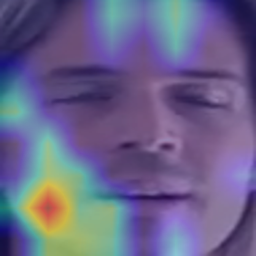

01_REAL_pred-FAKE_1.00.png


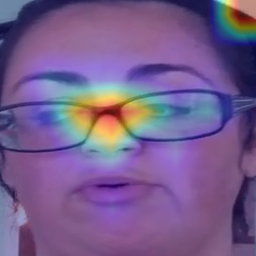

02_REAL_pred-REAL_0.85.png


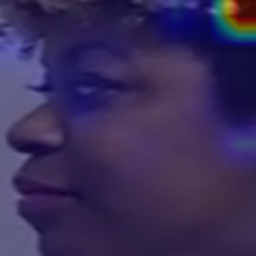

03_REAL_pred-REAL_0.02.png


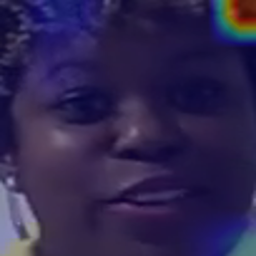

04_REAL_pred-FAKE_0.95.png


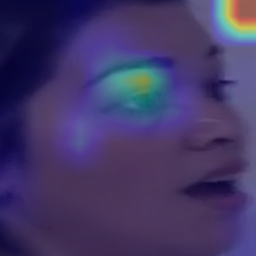

05_FAKE_pred-FAKE_1.00.png


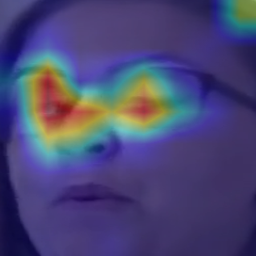

06_FAKE_pred-FAKE_0.97.png


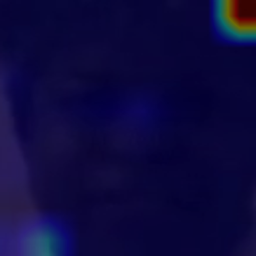

07_FAKE_pred-FAKE_1.00.png


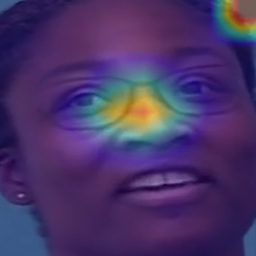

08_FAKE_pred-FAKE_0.89.png


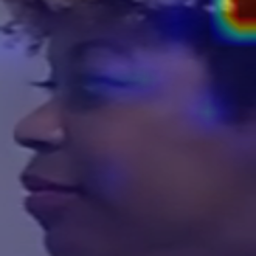

09_FAKE_pred-FAKE_1.00.png


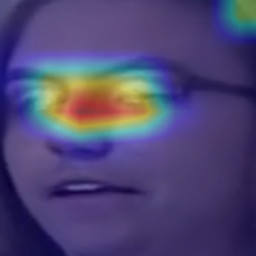

=== gradcam_meso4 ===
00_REAL_pred-REAL_0.33.png


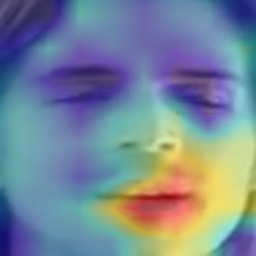

01_REAL_pred-FAKE_1.00.png


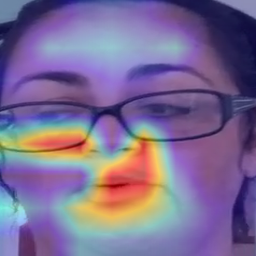

02_REAL_pred-FAKE_0.73.png


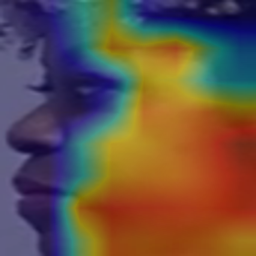

03_REAL_pred-FAKE_0.83.png


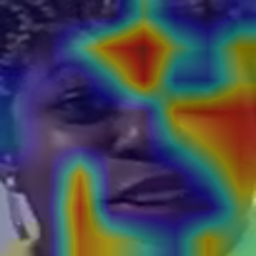

04_REAL_pred-REAL_0.44.png


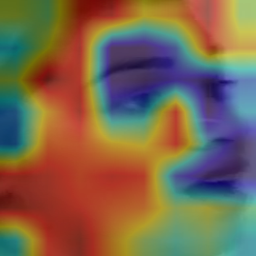

05_FAKE_pred-FAKE_0.99.png


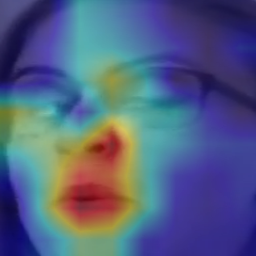

06_FAKE_pred-FAKE_0.95.png


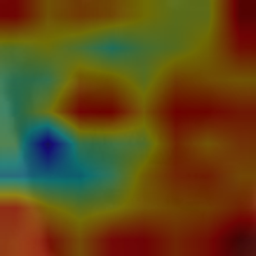

07_FAKE_pred-FAKE_1.00.png


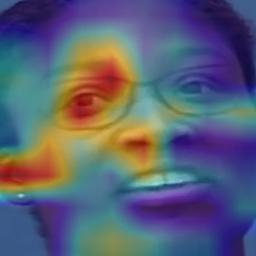

08_FAKE_pred-FAKE_0.87.png


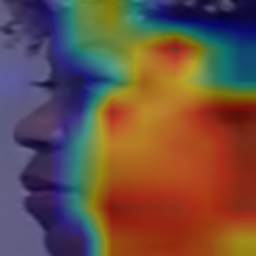

09_FAKE_pred-FAKE_0.96.png


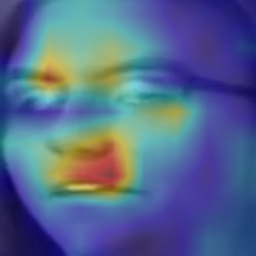

In [70]:
# 7c: Show Grad-CAM images
from pathlib import Path
from IPython.display import display, Image as IPImage
for d in ["gradcam_effb4", "gradcam_meso4"]:
    print(f"=== {d} ===")
    for img in sorted(Path(d).glob("*.png")):
        print(img.name); display(IPImage(filename=str(img), width=400))

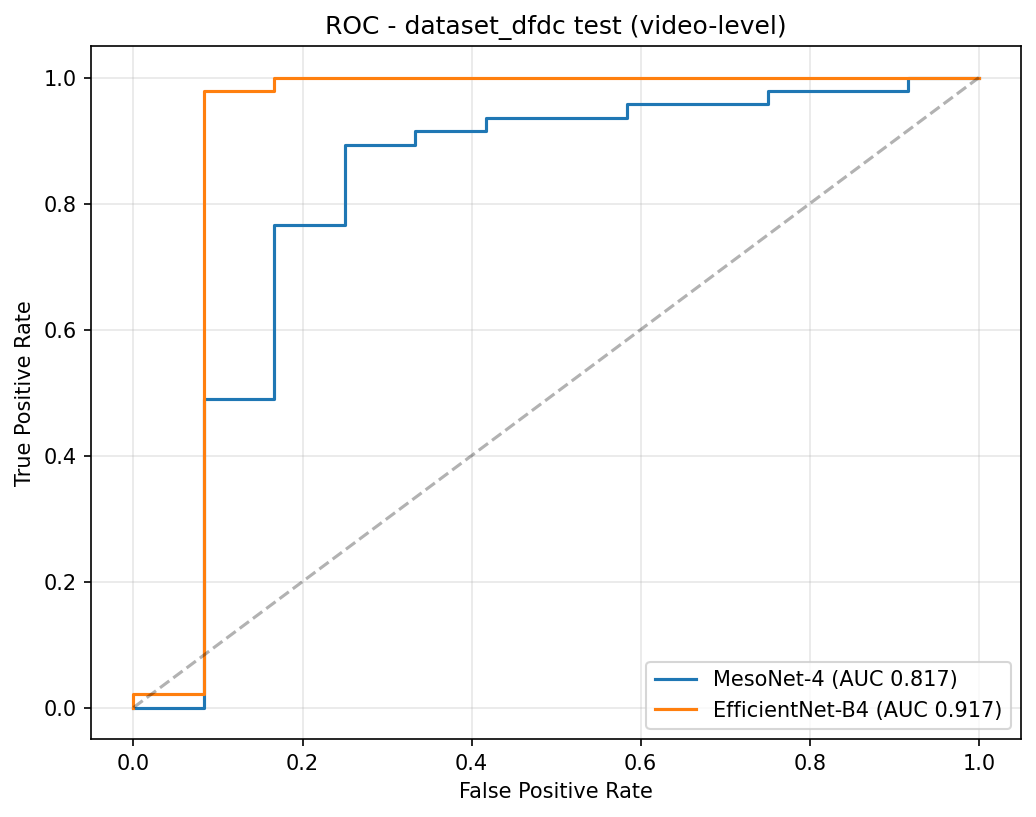

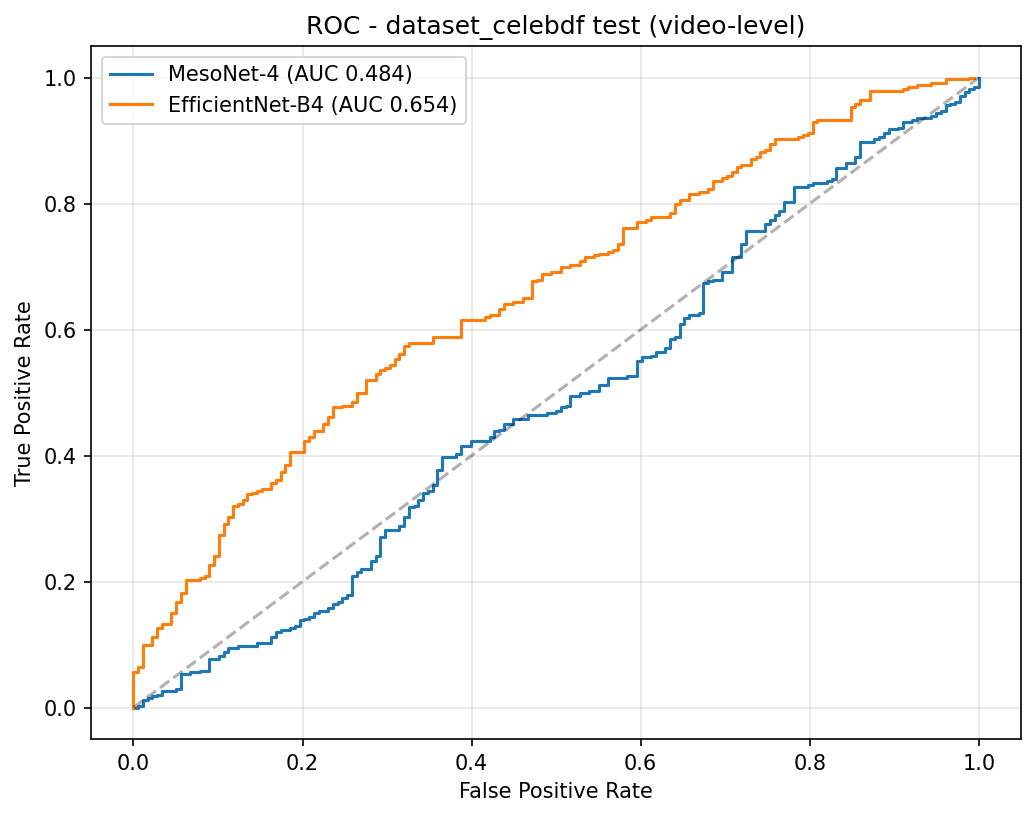

In [71]:
# 7d: Show ROC curves
from IPython.display import display, Image as IPImage
for f in ["plots/roc_dataset_dfdc.png", "plots/roc_dataset_celebdf.png"]:
    if Path(f).exists(): display(IPImage(filename=f, width=650))

---
## 8. Results Table
Built automatically from `results/*.json`. Video-level metrics; brackets are 95% bootstrap CIs.

In [72]:
# 8: Results comparison table
import json, math
from pathlib import Path
rows = [json.load(open(f)) for f in sorted(Path("results").glob("*.json"))]
order = {"dataset_dfdc": 0, "dataset_celebdf": 1}
name_order = {"MesoNet-4": 0, "EfficientNet-B4": 1, "Hybrid fusion": 2,
              "Eye LSTM": 3, "Late fusion (LogReg)": 4}
rows.sort(key=lambda r: (order.get(r["test_data"], 9), name_order.get(r["name"], 9)))
def fmt(m, k):
    v = m.get(k, float("nan"))
    if isinstance(v, float) and (math.isnan(v) or not math.isfinite(v)):
        return "—"
    ci = m.get("ci95", {}).get(k, [float("nan"), float("nan")])
    if math.isnan(ci[0]):
        return f"{v:.3f}"
    return f"{v:.3f} [{ci[0]:.2f}-{ci[1]:.2f}]"

print(f"{'Model':<26}{'Test data':<11}{'Videos':>8}  {'AUC':<21}{'Balanced acc':<21}{'F1':<21}")
print("-" * 108)
for r in rows:
    m = r["video"]; td = r["test_data"].replace("dataset_", "")
    print(f"{r['name']:<26}{td:<11}{m['n']:>8}  {fmt(m,'auc'):<21}{fmt(m,'bal_acc'):<21}{fmt(m,'f1'):<21}")
print("\nThresholds were tuned on the DFDC validation split only. In-dataset = DFDC test; cross-dataset = Celeb-DF.")


Model                     Test data    Videos  AUC                  Balanced acc         F1                   
------------------------------------------------------------------------------------------------------------
MesoNet-4                 dfdc             59  0.817 [0.62-0.97]    0.791 [0.64-0.92]    0.915 [0.85-0.97]    
EfficientNet-B4           dfdc             59  0.917 [0.73-1.00]    0.937 [0.84-1.00]    0.968 [0.92-1.00]    
Eye LSTM                  dfdc             59  0.282 [0.13-0.47]    0.372 [0.31-0.44]    0.745 [0.64-0.83]    
Late fusion (LogReg)      dfdc             59  0.917 [0.73-1.00]    0.937 [0.84-1.00]    0.968 [0.92-1.00]    
Hybrid Fusion             dfdc             59  0.922 [0.76-1.00]    0.937 [0.84-1.00]    0.968 [0.92-1.00]    
MesoNet-4                 celebdf         518  0.484 [0.43-0.54]    0.509 [0.48-0.54]    0.766 [0.73-0.80]    
EfficientNet-B4           celebdf         518  0.654 [0.60-0.70]    0.545 [0.52-0.58]    0.788 [0.75-0.82]    
Eye

---
## 9. Save Everything
Zips the results into `/kaggle/working`. Then click **Save Version → Save & Run All (Commit)**; the files appear under the version's **Output** tab, where you can download them.

Tip: the processed datasets are large. Delete `dataset_dfdc/` and `dataset_celebdf/` folders before committing only if you hit the 20 GB output limit — the zips below already contain everything needed for the report.

In [74]:
# 9: Zip results (kept as the notebook version's Output)
!zip -qr all_runs.zip runs/ results/ 2>/dev/null
!zip -qr plots_all.zip plots/ gradcam_effb4/ gradcam_meso4/ 2>/dev/null
!zip -qr eye_features_all.zip eye_dfdc/ eye_celebdf/ 2>/dev/null
!zip -qr scripts.zip *.py
!ls -lh *.zip
!du -sh /kaggle/working
print("Done - now click 'Save Version' (top right) to keep these outputs.")

-rw-r--r-- 1 root root 129M Nov  9 23:33 all_runs.zip
-rw-r--r-- 1 root root 540K Nov  9 23:33 eye_features_all.zip
-rw-r--r-- 1 root root 1.3M Nov  9 23:33 plots_all.zip
-rw-r--r-- 1 root root  26K Nov  9 23:33 scripts.zip
1022M	/kaggle/working
Done - now click 'Save Version' (top right) to keep these outputs.


In [76]:
import subprocess, os
os.chdir('/kaggle/working')

# Zip only the outputs — not the datasets
subprocess.run([
    'zip', '-r', 'all_outputs.zip',
    'runs/',           # model weights (.pt files)
    'results/',        # JSON metrics
    'plots/',          # ROC curves, confusion matrices
    'gradcam_effb4/',  # Grad-CAM images
    'gradcam_meso4/',
    'eye_dfdc/',       # eye features
    'eye_celebdf/',
], check=True)

print("Done! all_outputs.zip ready")

updating: eye_celebdf/ (stored 0%)
updating: eye_dfdc/ (stored 0%)
updating: gradcam_effb4/ (stored 0%)
updating: gradcam_meso4/ (stored 0%)
updating: plots/ (stored 0%)
updating: results/ (stored 0%)
updating: runs/ (stored 0%)
  adding: runs/meso4_dfdc/ (stored 0%)
  adding: runs/meso4_dfdc/history.csv (deflated 64%)
  adding: runs/meso4_dfdc/best.pt (deflated 12%)
  adding: runs/eye_dfdc/ (stored 0%)
  adding: runs/eye_dfdc/best.pt (deflated 13%)
  adding: runs/fusion_dfdc/ (stored 0%)
  adding: runs/fusion_dfdc/history.csv (deflated 56%)
  adding: runs/fusion_dfdc/best.pt (deflated 7%)
  adding: runs/effb4_dfdc/ (stored 0%)
  adding: runs/effb4_dfdc/history.csv (deflated 65%)
  adding: runs/effb4_dfdc/best.pt (deflated 7%)
  adding: results/meso4_dataset_celebdf.json (deflated 62%)
  adding: results/late_fusion_dataset_dfdc.json (deflated 57%)
  adding: results/effb4_dataset_dfdc.json (deflated 64%)
  adding: results/fusion_dataset_celebdf.json (deflated 55%)
  adding: results/eye_